## Analyze Data from Fischbach Lab 

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import patheffects
import scipy.optimize
import scipy.stats
from scipy.stats import gmean, ttest_rel, wilcoxon, ttest_ind
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from sklearn.cluster import SpectralClustering, KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler, RobustScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from math import erf
import multiprocessing as mp
import seaborn as sns
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

# set colors
ito_colors = [
    '#999999',   # Grey
    '#E69F00',  # Orange
    '#56B4E9',  # Sky Blue
    '#009E73',  # Bluish Green
    '#F0E442',  # Yellow
    '#0072B2',  # Blue
    '#D55E00',  # Vermillion
    '#CC79A7',  # Reddish Purple
    '#999933', # Olive
    '#AA4499' # Pink purple
]
custom_cmap_discrete = ListedColormap(ito_colors)

In [2]:
# 2. Define the scaling functions
def clr_transform(column):
    # Calculate the geometric mean of the column
    # gmean handles NaNs by default with 'omit', but ensure data is positive
    norm_colum = column/np.sum(column)
    col_gmean = gmean(norm_colum, nan_policy='omit')
    
    # Scale the column by dividing each value by the geometric mean
    scaled_column = norm_colum / col_gmean
    return np.log10(scaled_column)

def alr_transform(column, ref = 'first'):
    # Calculate the additive log tranform
    # Scale the column by dividing each value by the first cluster
    if ref == 'first':
        norm_column = column/column[0]
    elif ref == 'max':
        norm_column = column/np.amax(column)
        
    return np.log10(norm_column)

#### Import datasets

In [3]:
# bulk reactivity and cross-reactivity data from Nagashima et al. (2023)
coverage_data = pd.read_csv('./data/nagashima_fig2.csv')
coverage_data['strain_id'] = coverage_data['Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
coverage_data['imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_pval', 'hCom1d_pTreg_pval', 'hCom1d_FR4_Th_pval']] <= 0.05).any(axis="columns")
coverage_data['sig_imm_resp_flag'] = (coverage_data[['hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']] == 'Yes').any(axis="columns")

cross_reactivity_data = pd.read_csv('./data/nagashima_fig3.csv')
cross_reactivity_data['strain_id'] = cross_reactivity_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

hybridoma_abundance_data = pd.read_csv('./data/nagashima_hybridoma co-culture.csv')

# week 2 abundance data from Nagashima et al. (2023)
day14_abundance_data = pd.read_csv('./data/nagashima_extfig7a.csv')
day14_abundance_data['strain_id'] = day14_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

# amino acid dropout data from Cheng et al. (2022)
amino_dropout_abundance_data = pd.read_csv('./data/cheng_tableS3.csv')
amino_dropout_abundance_data['strain_id'] = amino_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
amino_dropout_abundance_data.loc[:,'day2_log10_abundance'] = amino_dropout_abundance_data.day2_abundance
amino_dropout_abundance_data.loc[:,'day2_abundance'] = 100*10**(amino_dropout_abundance_data.day2_abundance)

# abundance data from Wang et al. (2023)
day0_abundance_data = pd.read_csv('./data/wang_tableS2_inoculumB6mice.csv')
day0_abundance_data['strain_id'] = day0_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

feces_abundance_data = pd.read_csv('./data/wang_tableS2_fecesB6mice.csv')
feces_abundance_data['strain_id'] = feces_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
id_cols = ['Name', 'alt_Strain_Name', 'Phyla', 'strain_id']
keep_vars = ['Batch1_week1_m1', 'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4', 'Batch1_week1_m5',
        'Batch1_week2_m1', 'Batch1_week2_m2', 'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
        'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 'Batch1_week3_m4', 'Batch1_week3_m5',
        'Batch1_week4_m1', 'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4', 'Batch1_week4_m5',
            'Batch2_week4_m1', 'Batch2_week4_m2', 'Batch2_week4_m3', 
            'Batch3_week4_m1', 'Batch3_week4_m2', 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']
# fill zeros with minimum detectable value of 10-5
feces_abundance_data.loc[:, keep_vars] = np.maximum(feces_abundance_data[keep_vars], 1e-5)

feces_abundance_data_long = pd.wide_to_long(feces_abundance_data[id_cols + keep_vars], 
                stubnames = ["Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"],
                sep="_", suffix=r"\w+",
                i=id_cols[0], j="replicate").reset_index()

# strain dropout data from Wang et al. (2023)
strain_dropout_abundance_data = pd.read_csv('./data/wang_tableS3_cecum.csv')
strain_dropout_abundance_data['strain_id'] = strain_dropout_abundance_data['alt_Strain_Name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

# Combine data sets  
full_data = feces_abundance_data_long.loc[feces_abundance_data_long.strain_id.notna()].merge(day14_abundance_data[['strain_id', 'day14_abundance']], how = 'left', on = 'strain_id', validate = 'many_to_one',
                                ).merge(coverage_data[['strain_id', 'GF_pTreg_Average', 'hCom1d_pTreg_Average', 'GF_Th17_Average', 'hCom1d_Th17_Average', 'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average', 'imm_resp_flag', 'sig_imm_resp_flag']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       ).merge(day0_abundance_data.loc[day0_abundance_data.strain_id.notna(),['strain_id', 'day0_abundance_batch1', 'day0_abundance_batch2', 'day0_abundance_batch3']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       ).merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna(),['strain_id', 'day2_abundance']], how = 'left', on = 'strain_id', validate = 'many_to_one'
                                       )

In [4]:
# pd.set_option('display.max_rows', None)
# coverage_data[['strain_id', 'imm_resp_flag', 'hCom1d_pTreg_discovery', 'hCom1d_pTreg_discovery', 'hCom1d_FR4_Th_discovery']]

#### Microbial abundance data for week 0 (inoculum) to week 4 (post-inoculation)
This data comes from multiple sources

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/4172290904.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


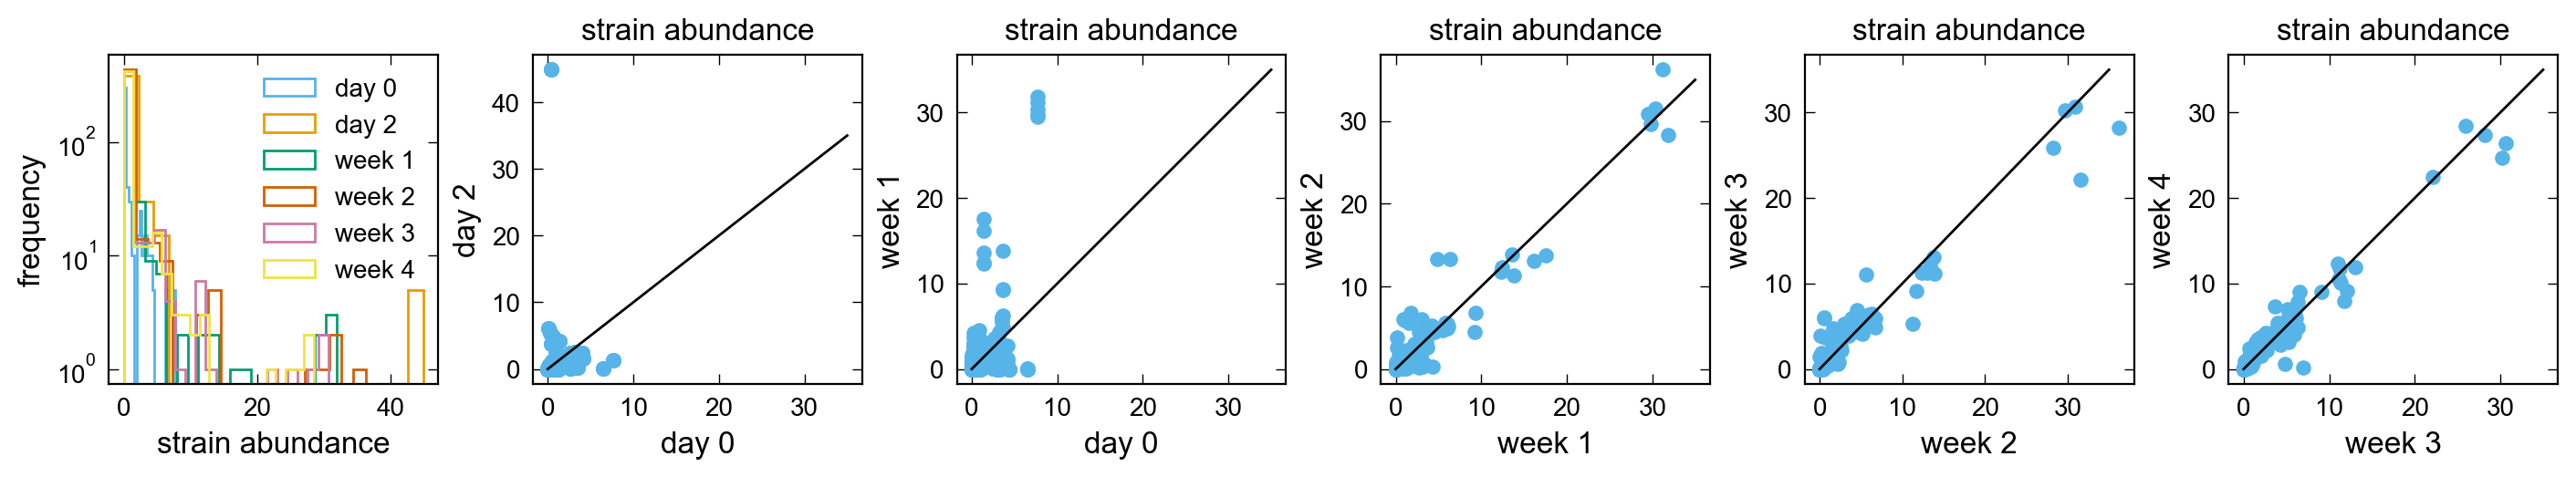

In [5]:
# Plot figures
fig, axs = plt.subplots(1, 6, figsize=(14.0, 3.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
var_list = [["day0_abundance_batch1", "day2_abundance"],
            ["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"]]

axs[0].hist(full_data.day0_abundance_batch1, bins = 20, log = True, histtype = 'step', label = 'day 0');
axs[0].hist(full_data.day2_abundance, bins = 20, log = True, histtype = 'step', label = 'day 2');
axs[0].hist(full_data.Batch1_week1, bins = 20, log = True, histtype = 'step', label = 'week 1');
axs[0].hist(full_data.Batch1_week2, bins = 20, log = True, histtype = 'step', label = 'week 2');
axs[0].hist(full_data.Batch1_week3, bins = 20, log = True, histtype = 'step', label = 'week 3');
axs[0].hist(full_data.Batch1_week4, bins = 20, log = True, histtype = 'step', label = 'week 4');

for i, u in enumerate(var_list):
    axs[i + 1].scatter(full_data[u[0]], full_data[u[1]], marker = 'o')
    # mask = ~np.isnan(full_data[u[0]]) & ~np.isnan(full_data[u[1]])
    # m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]][mask], full_data[u[1]][mask])
    # axs[i + 1].plot(np.unique(full_data[u[0]][mask]), m*np.unique(full_data[u[0]][mask]) + b, 
    #                 color = 'orange', label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.2f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
    axs[i + 1].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')

for j, ax in enumerate(axs.flat):
    ax.legend()
    if j >= 1:
        # ax.plot([0, 40], [0,40])
        # ax.semilogy()
        # ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/wk_change_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

Day 2 data from Cheng et al (2022) is weird. There's a big change in the abundance of Lactococcus lactis subsp. lactis Il1403 from day 0 to day 2 in the data. The inoculum (day 0) does not reflect anything about the ecology of the consortium as it is made by pooling samples of each microbe grown separately in an ideal medium.

##### Microbial abundance trajectories over time: week 0 to week 4
This data is for a microbial consortium that is very similar to hCom1d. The differences are all(?) very low abundance strains.

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/797908529.py:35: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig('_figs/fig_rel_abundance_dynamics_by_strain'+'.pdf', dpi=300, bbox_inches='tight')
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


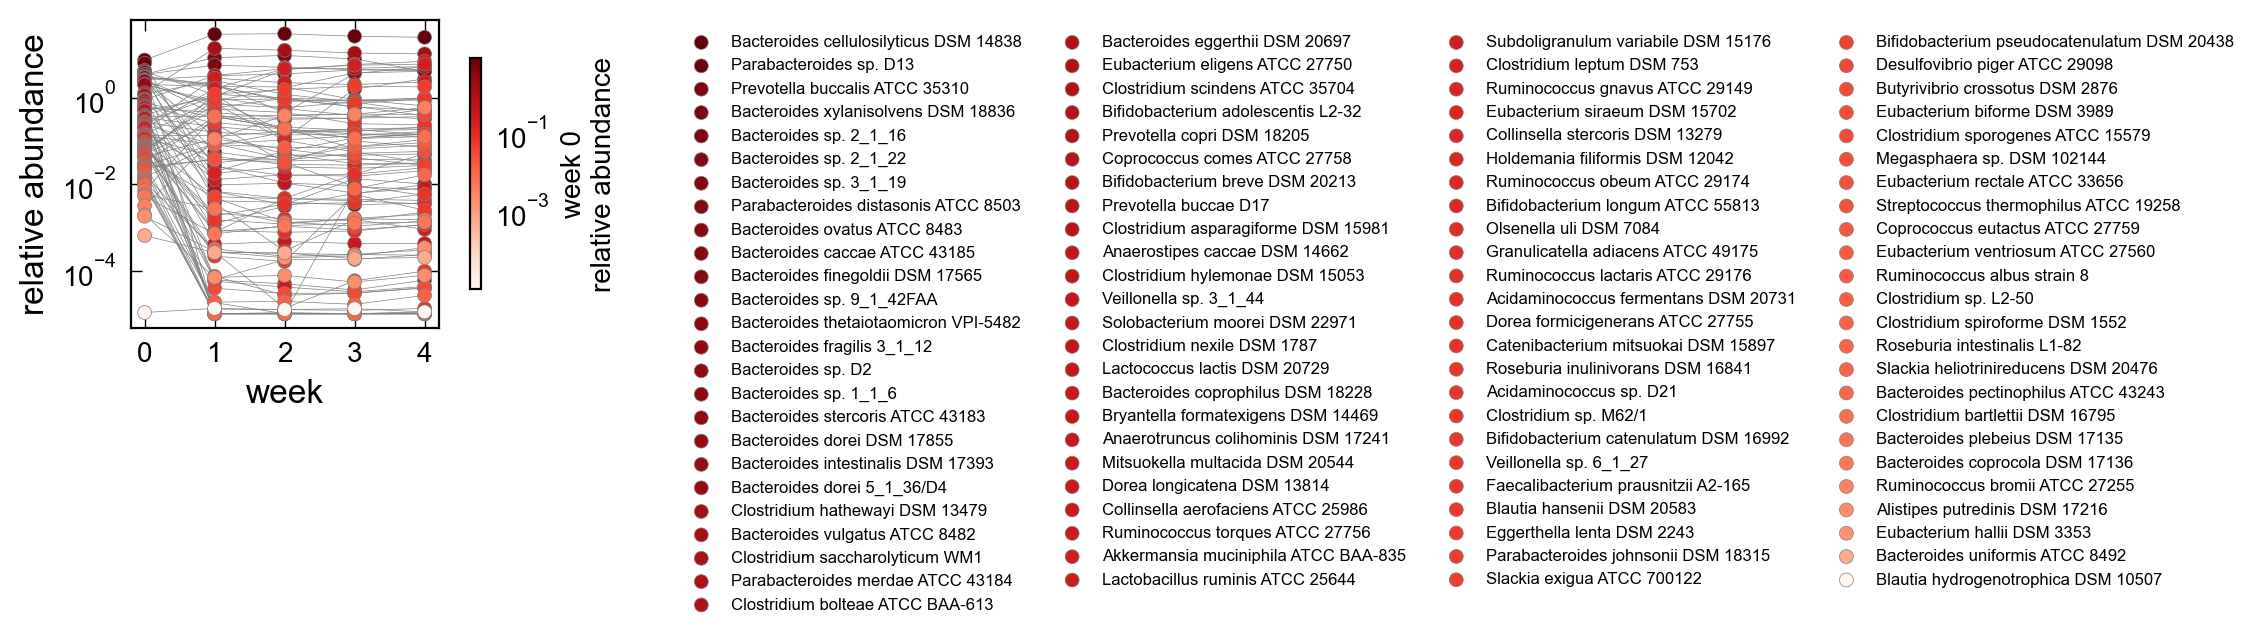

In [6]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(4.0, 2.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
vmin, vmax = np.amin(full_data.day0_abundance_batch1), np.amax(full_data.day0_abundance_batch1)
data = full_data[['Name'] + var_list].groupby('Name', as_index = False).mean()
strain_list = data.sort_values(by='day0_abundance_batch1', ascending= False).Name

for strain in strain_list:
    y_data = np.array(data.loc[data.Name == strain, var_list].values.ravel().tolist())
    mask = y_data > 0
    x_data = np.array([0, 1, 2, 3, 4])
    z_data = data.loc[data.Name == strain, var_list[0]].values.item()*np.ones(len(x_data))
    if np.amin(mask) > 0:
        ax.plot(x_data[mask], y_data[mask],  color = 'grey', linewidth = 0.25, zorder = 0)
        im = ax.scatter(x_data[mask], y_data[mask],  
                        marker = 'o', edgecolor = 'grey', linewidth = 0.25, 
                        c = z_data[mask], cmap = 'Reds', norm = mpl.colors.LogNorm(vmax = vmax, vmin = vmin), label = strain, zorder = 1)

    
ax.legend(bbox_to_anchor=(1.75, 1.0), fontsize=6, framealpha=0, ncol = 4)
cb = fig.colorbar(im, ax=ax, location='right', shrink = 0.75, pad = 0.05)
cb.set_label('week 0\nrelative abundance', fontsize = 10)
cb.ax.tick_params(labelsize=10)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)
ax.set_xticks(x_data)

fig.savefig('_figs/fig_rel_abundance_dynamics_by_strain'+'.pdf', dpi=300, bbox_inches='tight')

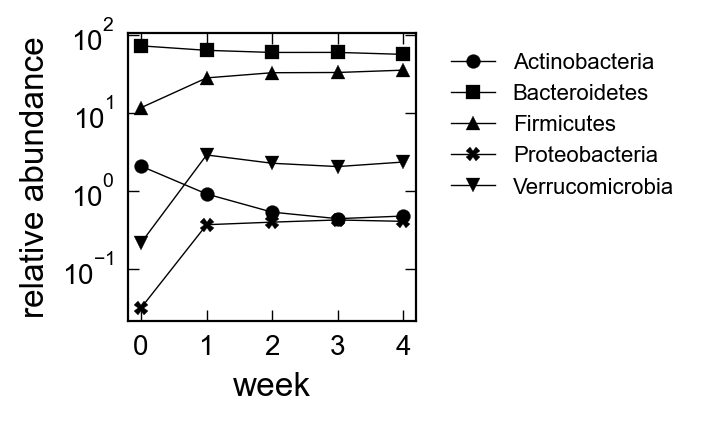

In [7]:
# Using mean data from Wang et al (2023)
fig, ax = plt.subplots(1, 1, figsize=(4.0, 2.0), sharex = False, constrained_layout=True)

var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
data = full_data[['Name', 'Phyla'] + var_list].groupby(['Name', 'Phyla'], as_index = False).mean().groupby('Phyla', as_index = False).sum()
phyla_list = np.unique(data.sort_values(by='Batch1_week1', ascending= False).Phyla)
markers = ['o','s', '^', 'X', 'v']

for i, phyla in enumerate(phyla_list):

    y_data = data.loc[data.Phyla == phyla, var_list].values.ravel().tolist()
    x_data = [0, 1, 2, 3, 4]
    ax.plot(x_data, y_data, marker = markers[i], linewidth = 0.5, label = phyla, color = 'black')
    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=8, framealpha=0)

ax.set_xlabel('week', fontsize = 12)
ax.set_ylabel('relative abundance', fontsize = 12)
ax.semilogy()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)
ax.set_xticks(x_data)

fig.savefig('_figs/fig_rel_abundance_dynamics_by_phyla'+'.pdf', dpi=300, bbox_inches='tight')

Fecal matter data from Wang et al. (2023) has more data points and more reliable trends. We'll use this going forward.

#### Reactivity of individual T-cell receptors to individual hCom1d microbes
This data comes from Figure 3 in Nagashima et al. (2023). Data is only available for a subset of the microbes.

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


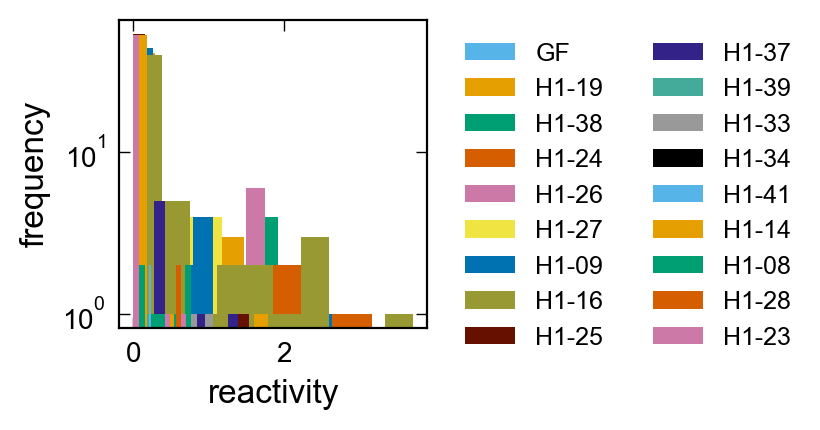

In [8]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.hist(pd.to_numeric(cross_reactivity_data[var]), bins = 10, log = True, label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('reactivity', fontsize = 12)
ax.set_ylabel('frequency', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

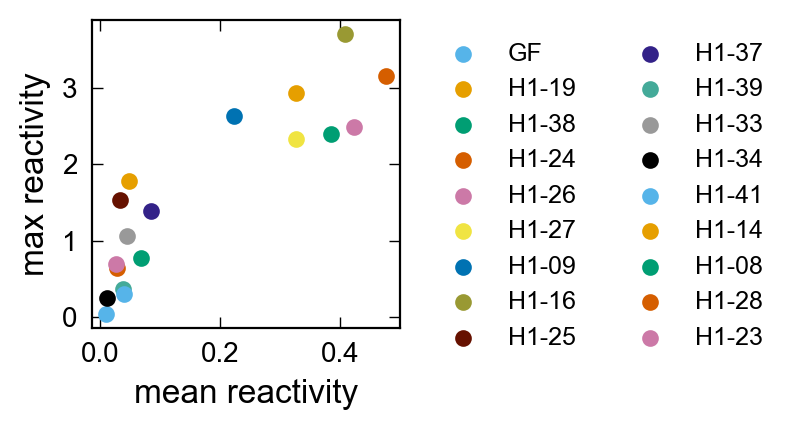

In [9]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = ['GF',
            'H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

for var in var_list:
    ax.scatter(np.mean(pd.to_numeric(cross_reactivity_data[var])), np.max(pd.to_numeric(cross_reactivity_data[var])), label = var);

    
ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0, ncol = 2)

ax.set_xlabel('mean reactivity', fontsize = 12)
ax.set_ylabel('max reactivity', fontsize = 12)
    
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

#### Immune coverage of hCom1d by T-cell repertoire
This data comes from Figure 2 in Nagashima et al. (2023).

5.294537922539403e-29
8.53789293918939e-33
0.0066796200314578145


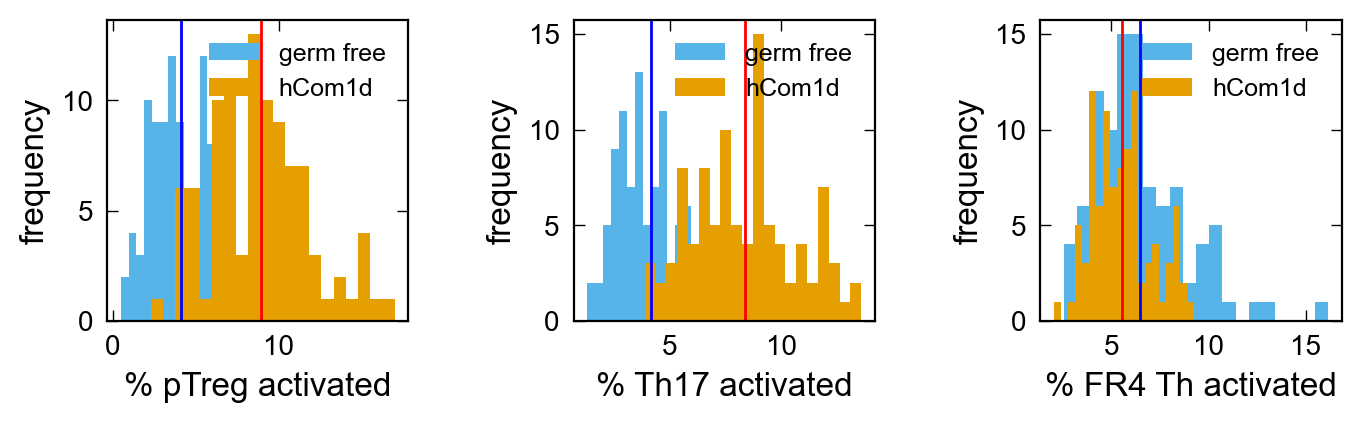

In [10]:
# Plot figures
fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

data = full_data[['Name'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, var in enumerate(var_list):
    GF_pop, hcom1_pop = data[var[0]], data[var[1]]
    axs[i].hist(GF_pop, bins = 20, label = 'germ free');
    axs[i].hist(hcom1_pop, bins = 20, label = 'hCom1d');
    axs[i].axvline(x = np.mean(GF_pop), color = 'blue')
    axs[i].axvline(x = np.mean(hcom1_pop), color = 'red')

    axs[i].legend(fontsize=9, loc = 'upper right', framealpha=0)
    
    axs[i].set_xlabel(['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][i], fontsize = 12)
    axs[i].set_ylabel('frequency', fontsize = 12)
        
    axs[i].set_box_aspect(1)
    axs[i].minorticks_off()
    axs[i].tick_params(axis='both', which='major', labelsize=10)
    axs[i].xaxis.set_tick_params(labeltop=False)

    # Run two-sided Mann-Whitney test with null that the two distribitions are identical
    from scipy.stats import mannwhitneyu
    U1, p = mannwhitneyu(GF_pop, hcom1_pop, method="exact")
    print(p)

fig.savefig('_figs/fig_immune_activation_GF_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

What if we look at non-immunogenic and immunogenic microbes? What about individual clusters? Can we detect a signal at that level?

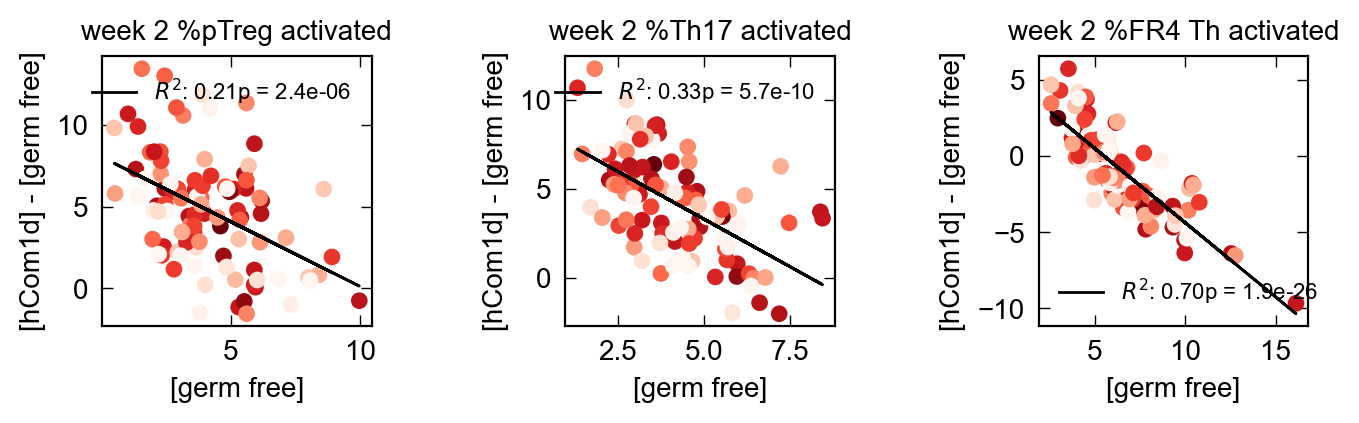

In [11]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):

    ax.scatter(data[coverage_variables[2*i]], 
               data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]],
                c = data['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    #ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(data[coverage_variables[2*i]], data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]])
    ax.plot(data[coverage_variables[2*i]], 
            m*data[coverage_variables[2*i]] + b,
            color = 'black',
           label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + f'p = {p_value:.1e}')
    
for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('[germ free]', fontsize = 10)
    ax.set_ylabel('[hCom1d] - [germ free]', fontsize = 10)
    ax.set_title('week 2 '+['%pTreg activated', '%Th17 activated', '%FR4 Th activated'][j], fontsize = 10)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_change_in_response_to_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

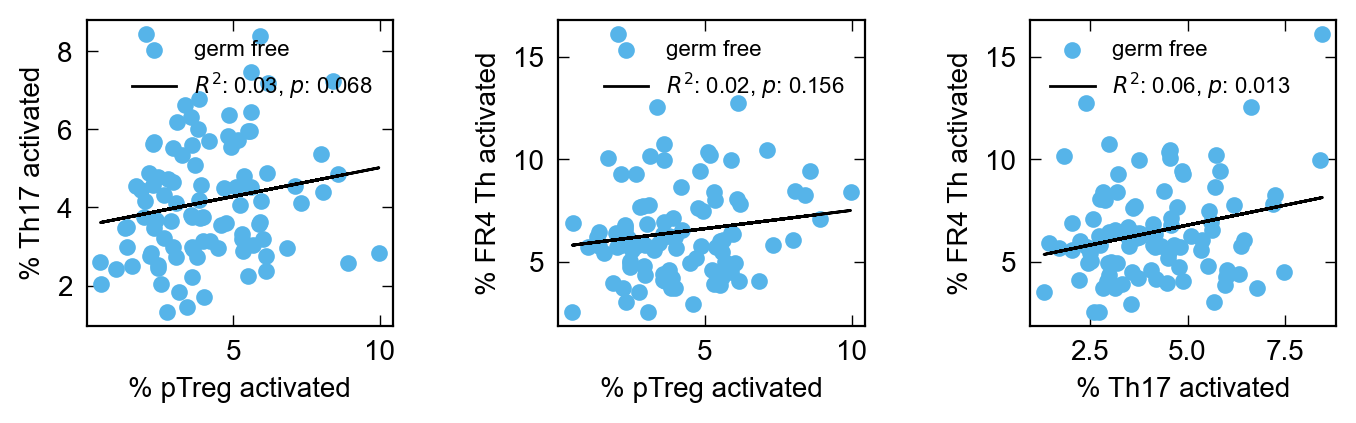

In [12]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[coverage_variables[0], coverage_variables[2]],
            [coverage_variables[0], coverage_variables[4]],
            [coverage_variables[2], coverage_variables[4]]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

axs[0].scatter(data[coverage_variables[0]], data[coverage_variables[2]], marker = 'o', label = 'germ free')
axs[1].scatter(data[coverage_variables[0]], data[coverage_variables[4]], marker = 'o', label = 'germ free')
axs[2].scatter(data[coverage_variables[2]], data[coverage_variables[4]], marker = 'o', label = 'germ free')

for i, u in enumerate(var_list):
    m, b, r_value, p_value, std_err = scipy.stats.linregress(data[u[0]], data[u[1]])
    axs[i].plot(data[u[0]], m*data[u[0]] + b, color = 'black', 
                label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    ax.set_xlabel(labels[j][0], fontsize = 10)
    ax.set_ylabel(labels[j][1], fontsize = 10)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

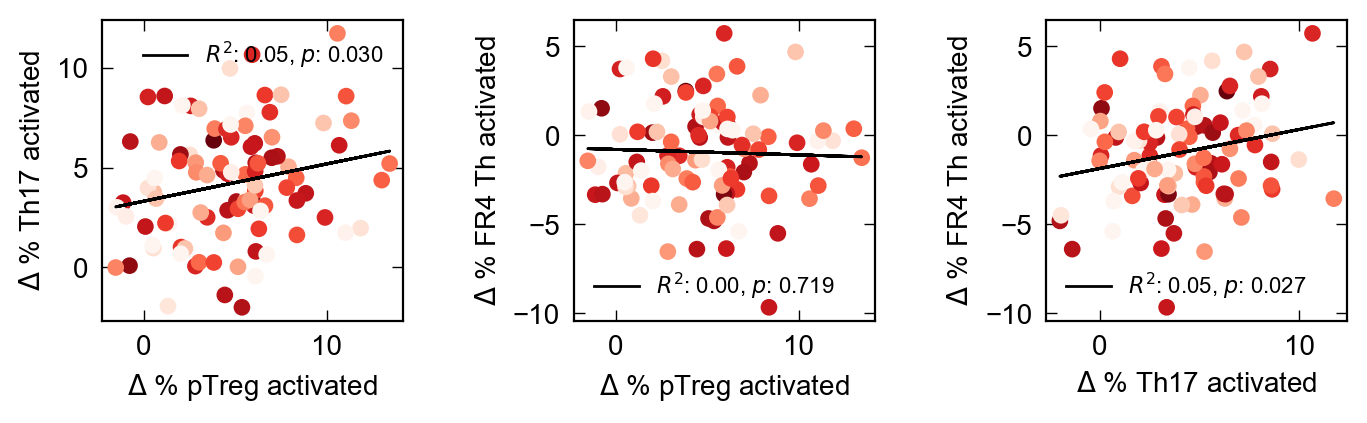

In [13]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[1, 3],
            [1, 5],
            [3, 5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, u in enumerate(var_list):
    x_data = data[coverage_variables[u[0]]] - data[coverage_variables[u[0] - 1]]
    y_data = data[coverage_variables[u[1]]] - data[coverage_variables[u[1] - 1]]
    axs[i].scatter(x_data, y_data, marker = 'o', c = data['Batch1_week1'],
               cmap = 'Reds', norm = mpl.colors.LogNorm())
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data, y_data)
    axs[i].plot(x_data, m*x_data + b, color = 'black', 
                label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize=8)
    ax.set_xlabel(r'$\Delta$ ' + labels[j][0], fontsize = 10)
    ax.set_ylabel(r'$\Delta$ ' + labels[j][1], fontsize = 10)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_relationship_immune_cells_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

What if we do these regressions only on the most abundant microbes? Or stratified by abundance level

#### Is there a relationship between microbe abundance and immune coverage?

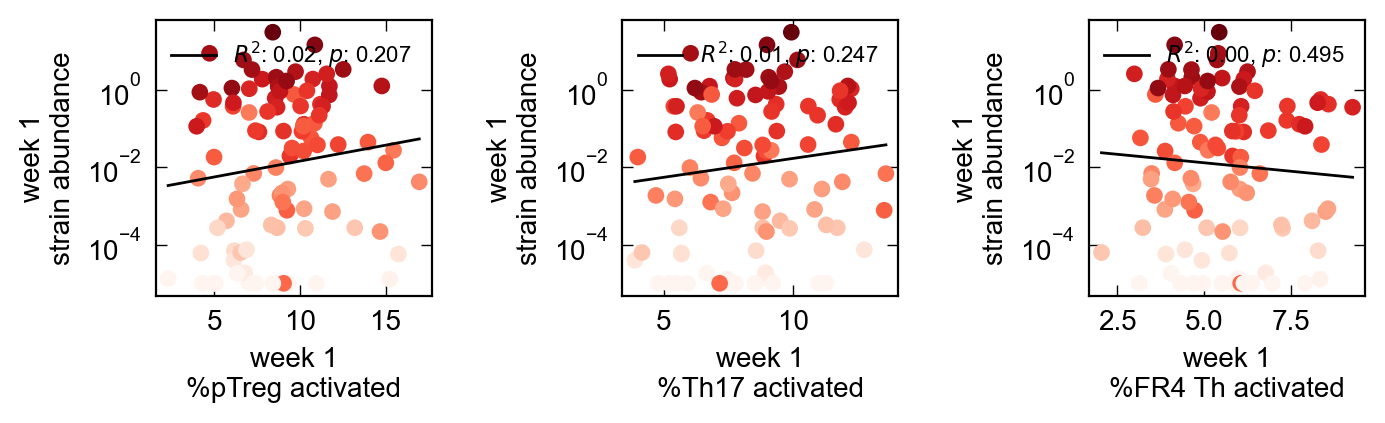

In [14]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

var_list = [coverage_variables[1], coverage_variables[3], coverage_variables[5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week4'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):
    x_data = data[coverage_variables[2*i + 1]]
    y_data = data['Batch1_week1']
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week4'],
               cmap = 'Reds',
               marker = 'o', norm = mpl.colors.LogNorm()) #, label = 'hCom1d')
    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black', 
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    ax.semilogy()
    ax.set_ylabel('week 1\nstrain abundance', fontsize = 10)
    ax.set_xlabel('week 1\n'+['%pTreg activated', '%Th17 activated', '%FR4 Th activated'][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_wk1_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

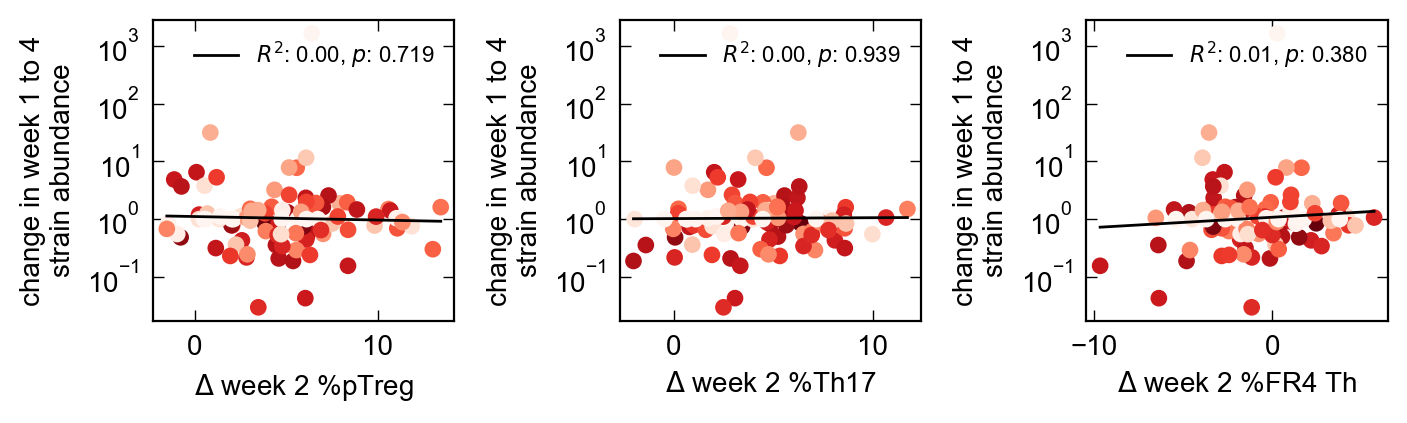

In [15]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week4'] + coverage_variables].groupby('Name', as_index = False).mean()

for i, ax in enumerate(axs):
    x_data = data[coverage_variables[2*i + 1]] - data[coverage_variables[2*i]]
    y_data = data['Batch1_week4']/data['Batch1_week1']
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week1'],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # ax.scatter(x_data[mask], m*x_data[mask] + b)
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    ax.semilogy()
    # ax.semilogx()
    ax.set_ylabel('change in week 1 to 4\nstrain abundance', fontsize = 10)
    ax.set_xlabel(r'$\Delta$ week 2 '+['%pTreg', '%Th17', '%FR4 Th'][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

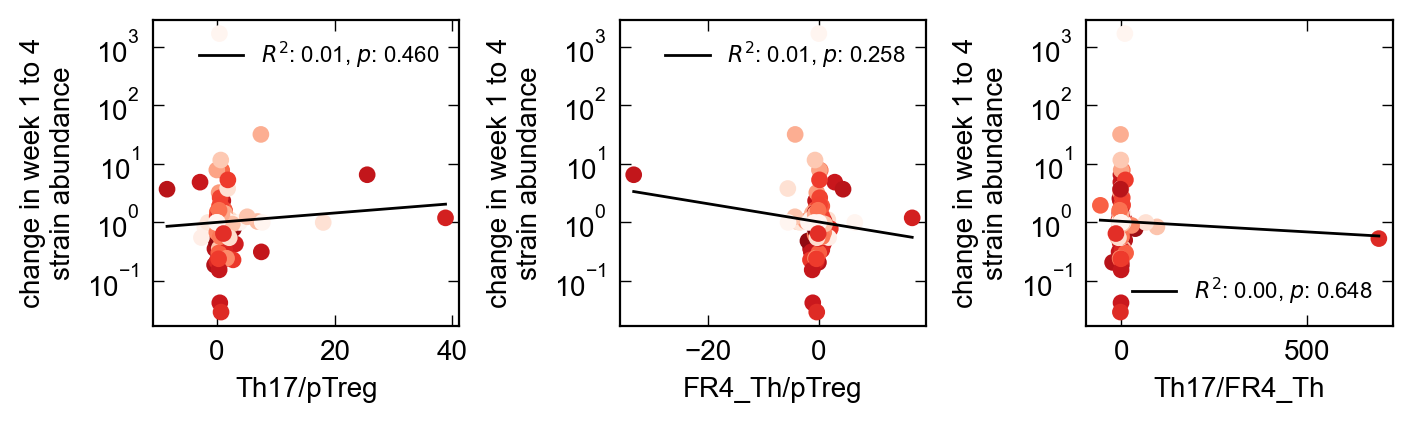

In [16]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week4'] + coverage_variables].groupby('Name', as_index = False).mean()
data.loc[:, "Th17_pTreg"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "FR4_Th_pTreg"] = ((data[coverage_variables[5]] - data[coverage_variables[4]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "Th17_FR4_Th"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[5]] - data[coverage_variables[4]])).values
var_list = ["Th17_pTreg", "FR4_Th_pTreg", "Th17_FR4_Th"]

for i, ax in enumerate(axs):
    x_data = data[var_list[i]]
    y_data = data['Batch1_week4']/data['Batch1_week1']
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week1'],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # regression
    ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black',
            label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.legend(fontsize = 8)
    ax.semilogy()
    # ax.semilogx()
    ax.set_ylabel('change in week 1 to 4\nstrain abundance', fontsize = 10)
    ax.set_xlabel(["Th17/pTreg", "FR4_Th/pTreg", "Th17/FR4_Th"][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

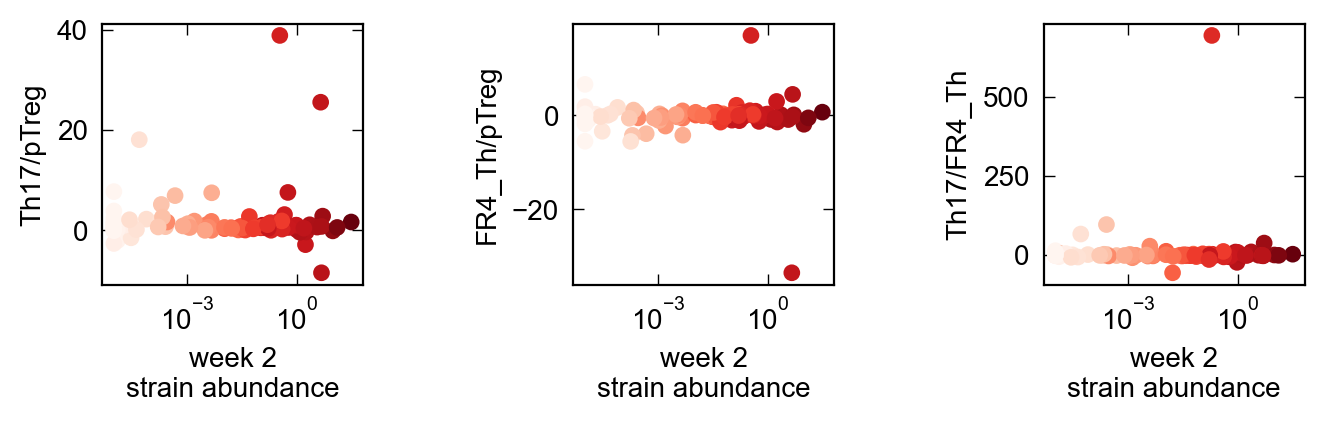

In [17]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

data = full_data[['Name', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3'] + coverage_variables].groupby('Name', as_index = False).mean()
data.loc[:, "Th17_pTreg"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "FR4_Th_pTreg"] = ((data[coverage_variables[5]] - data[coverage_variables[4]])/(data[coverage_variables[1]] - data[coverage_variables[0]])).values
data.loc[:, "Th17_FR4_Th"] = ((data[coverage_variables[3]] - data[coverage_variables[2]])/(data[coverage_variables[5]] - data[coverage_variables[4]])).values
var_list = ["Th17_pTreg", "FR4_Th_pTreg", "Th17_FR4_Th"]

for i, ax in enumerate(axs):
    x_data = data['Batch1_week2']
    y_data = data[var_list[i]]
    ax.scatter(x_data, 
               y_data, 
               c = data['Batch1_week1'],
               norm = mpl.colors.LogNorm(),
               cmap = 'Reds',
               marker = 'o')

    # mask = ~np.isnan(x_data) & ~np.isnan(y_data) & ~np.isinf(np.log10(y_data))
    # m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], np.log10(y_data[mask]))
    # # regression
    # ax.plot(np.unique(x_data[mask]), 10**(m*np.unique(x_data[mask]) + b), color = 'black',
    #         label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $p$: ' + str("{:.3f}".format(p_value)))

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.set_xlabel('week 2\nstrain abundance', fontsize = 10)
    ax.set_ylabel(["Th17/pTreg", "FR4_Th/pTreg", "Th17/FR4_Th"][j], fontsize = 10)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_change_in_wk2_abundance_v_coverage_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

In [18]:
# Compare compositional variance of individual microbes and microbes targeted by the same receptors.
# Hypothesis is that collective abundance of targeted microbes should vary much less than individual abundance
# Contrast this with grouping by Phylum (or other genetic data) and random shuffling
# How can I measure this? Do I have the data?

#### Ecology of the microbial community
Using amino acid dropouts (Cheng et al. (2022)) and strain drop outs (Wang et al. (2023).

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


[0.82832972 0.12783305 0.04383723]


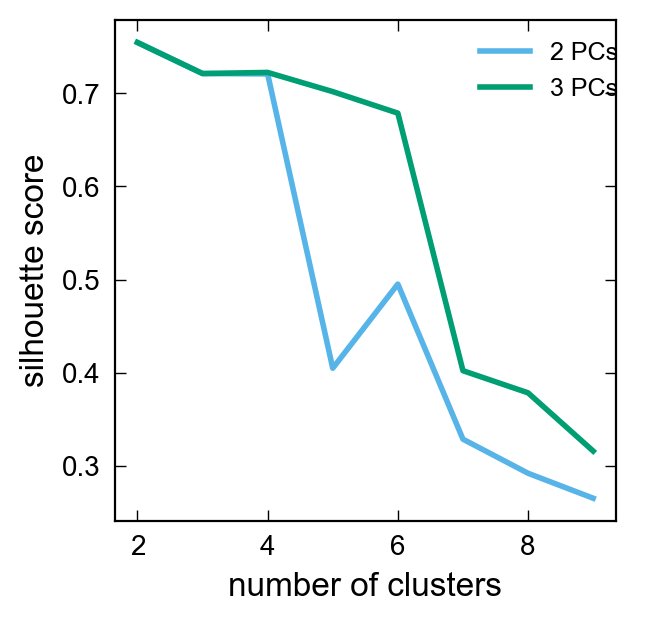

In [19]:
# Cluster based on strain drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
input_data = strain_dropout_abundance_data[cluster_vars + ['week3_cecum_abundance']].sort_values(by='week3_cecum_abundance', ascending= False).apply(alr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['week3_cecum_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(cosine_similarity(cluster_input[cluster_vars].values[mask]))
# pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering

for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.48273297 0.18990013 0.11427016 0.07654829 0.04903402 0.03680127
 0.01987872 0.01246154 0.00756792 0.00607626 0.00472872]


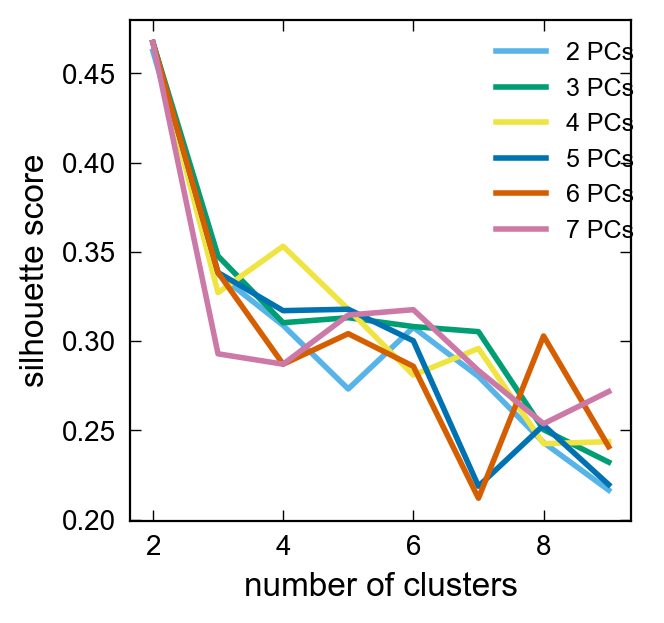

In [20]:
# Cluster based on amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine']
# ['Alanine', 'Arginine', 'Asparagine',
#        'AsparticAcid','GlutamicAcid', 'Glutamine', 'Glycine', # removed cysteine
#        'Histidine', 'Isoleucine', 'Leucine', 'Lysine', 'Methionine',
#        'Phenylalanine', 'Proline', 'Serine', 'Threonine', 'Tryptophan',
#        'Tyrosine', 'Valine']

input_data = 10**(amino_dropout_abundance_data[cluster_vars + ['day2_log10_abundance']].sort_values(by='day2_log10_abundance', ascending= False).fillna(-6)).apply(alr_transform, axis=0).fillna(0)

cluster_input = input_data[cluster_vars].sub(input_data['day2_log10_abundance'], axis=0)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


[5.41163954e-01 1.57242085e-01 1.03038704e-01 8.47014648e-02
 4.25614794e-02 2.91209516e-02 1.41324436e-02 1.11973877e-02
 7.00021414e-03 3.85336659e-03 2.53562812e-03 1.51182969e-03
 8.20995259e-04 5.86512378e-04 5.32983539e-04]


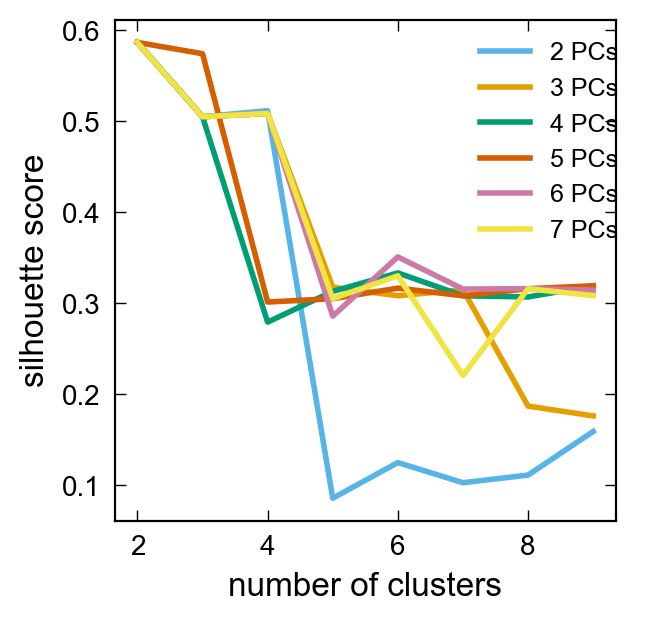

In [21]:
# Cluster based on combined strain and amino acid drop outs
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
amino_vars = ['Cysteine','Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine']
strain_vars = ['drop_Ch_abundance','drop_Cs_abundance','drop_ChCs_abundance']
cluster_vars = amino_vars + strain_vars

input_data = strain_dropout_abundance_data.loc[strain_dropout_abundance_data.strain_id.notna(), strain_vars + ['strain_id','week3_cecum_abundance']].merge(amino_dropout_abundance_data.loc[amino_dropout_abundance_data.strain_id.notna()], 
                                                                                                      how = 'left', on = 'strain_id', validate = 'one_to_one'
                                       ).sort_values(by='week3_cecum_abundance', ascending= False)
input_data[amino_vars + ['day2_log10_abundance']] = 10**(input_data[amino_vars + ['day2_log10_abundance']].fillna(-6)).apply(alr_transform, axis=0).fillna(0)
input_data[strain_vars + ['week3_cecum_abundance']] = input_data[strain_vars + ['week3_cecum_abundance']].apply(alr_transform, axis=0).fillna(0)

cluster_input = pd.concat([input_data[amino_vars].sub(input_data['day2_log10_abundance'], axis=0), 
                               input_data[strain_vars].sub(input_data['week3_cecum_abundance'], axis=0)],
                              axis = 1)
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
scaler = RobustScaler()
scaler.fit(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(scaler.transform(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = PCA(n_components=l).fit_transform(scaler.transform(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, label = str(l)+' PCs', linewidth = 2.0)

axs.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)

axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

[0.28042783 0.17463618 0.14137464 0.08553668 0.07610377 0.06312062
 0.05529092 0.04266415 0.02946972 0.02667738 0.00790391 0.00652693
 0.00340968 0.00241826 0.0021046  0.00140918 0.00092555]


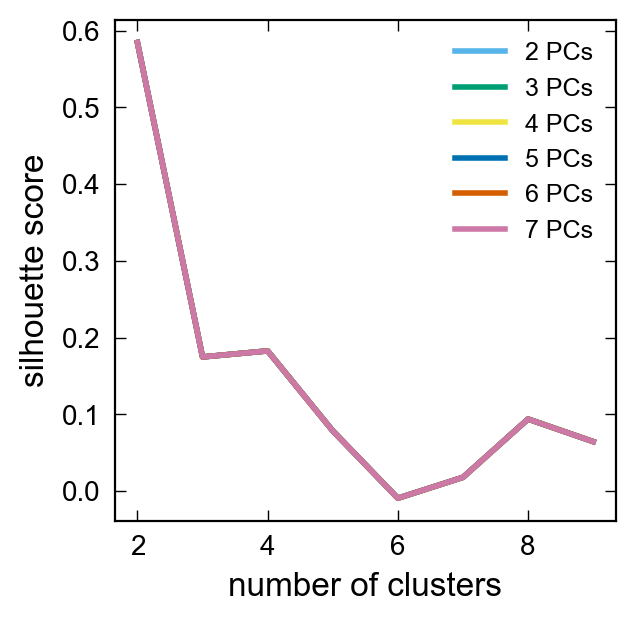

In [22]:
# Cluster based on immune receptor binding
fig, axs = plt.subplots(1,1, figsize=(4, 3.0), sharex='row', sharey=False,layout='constrained')

# Scale and center data for clustering
cluster_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39','H1-33','H1-34',
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

#cluster_input = np.log10(cross_reactivity_data[cluster_vars]/np.mean(cross_reactivity_data['GF'])).replace([-np.inf], 0.0)
cluster_input = cross_reactivity_data[cluster_vars]# - np.mean(cross_reactivity_data['GF'])
mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars)
# scaler = RobustScaler()
# scaler.fit(cluster_input[cluster_vars].values[mask])
normalizer = Normalizer(norm='l2')
cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars].values[mask])
# do PCA
pca = PCA(n_components=len(cluster_vars))
pca.fit(cluster_input_norm)
#pca.fit(cosine_similarity(cluster_input[cluster_vars].values[mask]))
print(pca.explained_variance_ratio_)
# dataset for clustering
for l in np.arange(2, np.minimum(len(cluster_vars), 7) + 1):
    for_clustering = cluster_input_norm #PCA(n_components=l).fit_transform(cluster_input_norm)
    #for_clustering = PCA(n_components=l).fit_transform(cosine_similarity(cluster_input[cluster_vars].values[mask]))
    cluster_iter = np.arange(2,10)
    score = []
    # compute scores
    for k in cluster_iter:
        clustering_object = KMeans(n_clusters=k, n_init = 10, random_state=0)
        score += [silhouette_score(cluster_input[cluster_vars].values[mask], clustering_object.fit_predict(for_clustering))]
        
    axs.plot(cluster_iter, score, color = ito_colors[l], label = str(l)+' PCs', linewidth = 2.0)

axs.legend(fontsize=9, framealpha=0)
axs.set_xlabel('number of clusters', fontsize = 12)
axs.set_ylabel('silhouette score', fontsize = 12)
axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)

#plt.savefig('_figs/figSI_'+comment+'-cluster_silhouette_scores'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


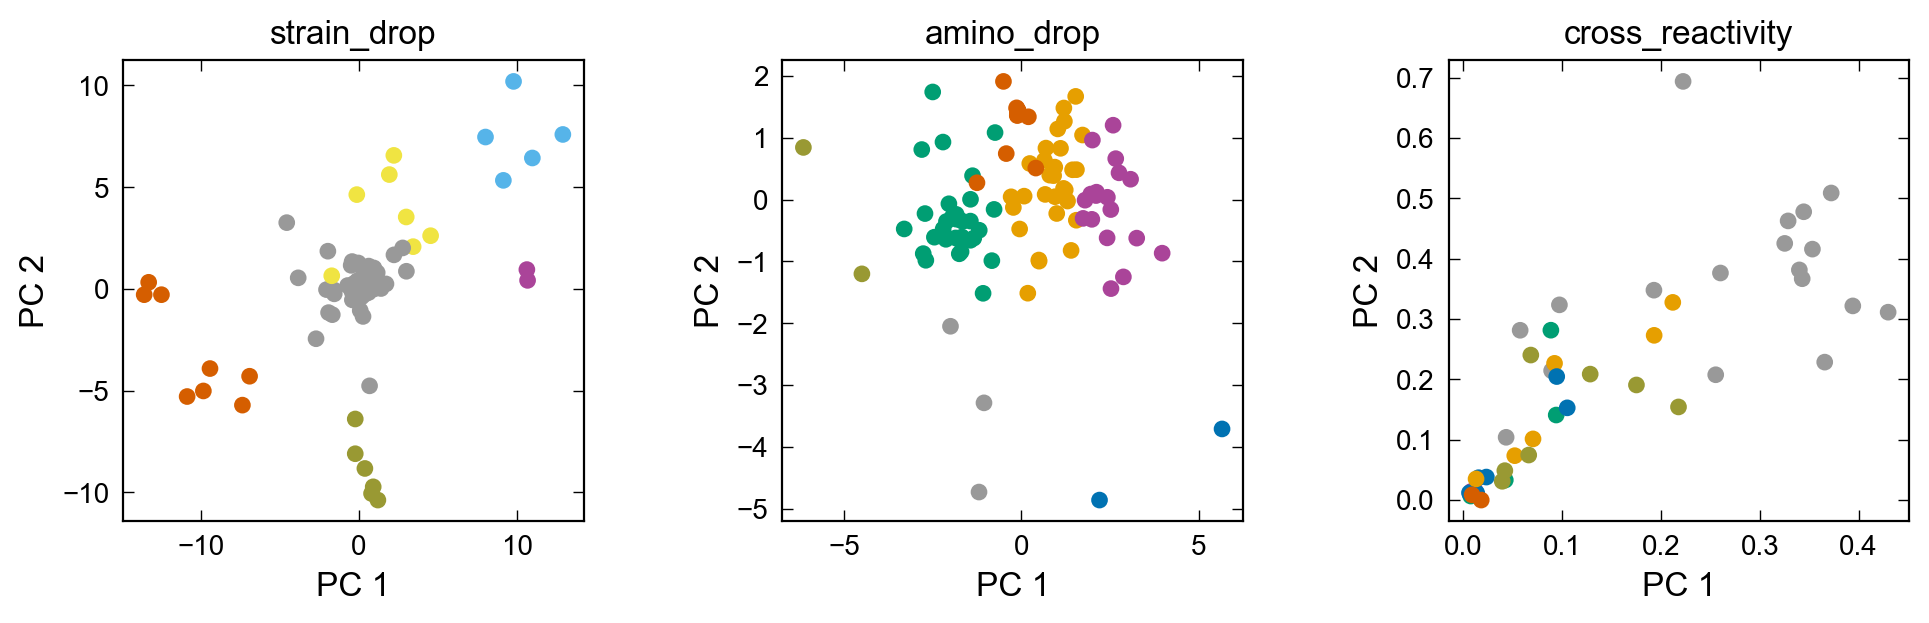

In [23]:
df_list = [strain_dropout_abundance_data, amino_dropout_abundance_data, cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()]]
cluster_vars_list = [['drop_Ch_abundance','drop_Cs_abundance', 'drop_ChCs_abundance'],
                     ['Cysteine', 'Methionine', 'Histidine', 'Isoleucine', 'Arginine', 'Valine',
                'Tyrosine', 'Leucine', 'Serine', 'Tryptophan', 'Proline', 'Glutamine'],
                     ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
                      'H1-25',
                      'H1-37','H1-39','H1-33','H1-34',
                      'H1-41','H1-14','H1-08',
                      'H1-28',
                      'H1-23']]
reference_vars_list = ['week3_cecum_abundance', 'day2_log10_abundance','GF']
label_list = ['strain_drop','amino_drop','cross_reactivity']
cluster_num_list = [6,7,7]
pca_num_list = [3,3,4]
full_data_w_clusters = full_data

fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.0), sharex = False, constrained_layout=True)


for i, df in enumerate(df_list):
    if i == 0:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]].sort_values(by=reference_vars_list[i], ascending= False).apply(alr_transform, axis=0).fillna(0).replace([-np.inf], 0.0)
        scaler = RobustScaler()
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = scaler.transform(cluster_input[cluster_vars_list[i]].values[mask])
    elif i == 1:
        input_data = 10**(df[cluster_vars_list[i] + [reference_vars_list[i]]].fillna(-6)).sort_values(by=reference_vars_list[i], ascending= False).apply(alr_transform, axis=0).fillna(0).replace([-np.inf], 0.0)
        scaler = RobustScaler()
        cluster_input = input_data[cluster_vars_list[i]].sub(input_data[reference_vars_list[i]], axis=0)
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        scaler.fit(cluster_input[cluster_vars_list[i]].values[mask])
        for_clustering = PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))
    else:
        input_data = df[cluster_vars_list[i] + [reference_vars_list[i]]]
        normalizer = Normalizer(norm='l2')
        cluster_input = input_data[cluster_vars_list[i]]
        mask = np.sum(~np.isnan(cluster_input) & ~np.isinf(cluster_input), axis = 1) == len(cluster_vars_list[i])
        cluster_input_norm = normalizer.fit_transform(cluster_input[cluster_vars].values[mask])
        for_clustering = cluster_input_norm #PCA(n_components=pca_num_list[i]).fit_transform(scaler.transform(cluster_input[cluster_vars_list[i]].values[mask]))

    cluster_input['strain_id'] = df.sort_values(by=reference_vars_list[i], ascending= False)['strain_id'] 
    clustering_object = KMeans(n_clusters=cluster_num_list[i], n_init = 10, random_state=0)
    clustering = clustering_object.fit(for_clustering)
    cluster_input.loc[mask,label_list[i]+'_cluster'] = (clustering.labels_ + 1).astype('int64')
    full_data_w_clusters = full_data_w_clusters.merge(cluster_input.loc[cluster_input.strain_id.notna(),['strain_id', label_list[i]+'_cluster'] + (cluster_vars_list[i] if i == 0 else [])], 
                               how = 'left', on = 'strain_id', validate = 'many_to_one')

    full_data_w_clusters.loc[:,label_list[i]+'_cluster'] = full_data_w_clusters[label_list[i]+'_cluster'].fillna(0).astype('int64')

    # Make plots
    axs[i].scatter(for_clustering[:,0], for_clustering[:,1],
                c = clustering.labels_,
              cmap = custom_cmap_discrete)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel(r'PC 1', fontsize = 12)
    ax.set_ylabel(r'PC 2', fontsize = 12)
    ax.set_title(label_list[j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/2712278464.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hybridoma_cluster_data.loc[:,'total_Treg'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].total_Treg.item() for var in receptor_bind_vars], axis = 0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/2712278464.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hybridoma_cluster_data.loc[:,'tota

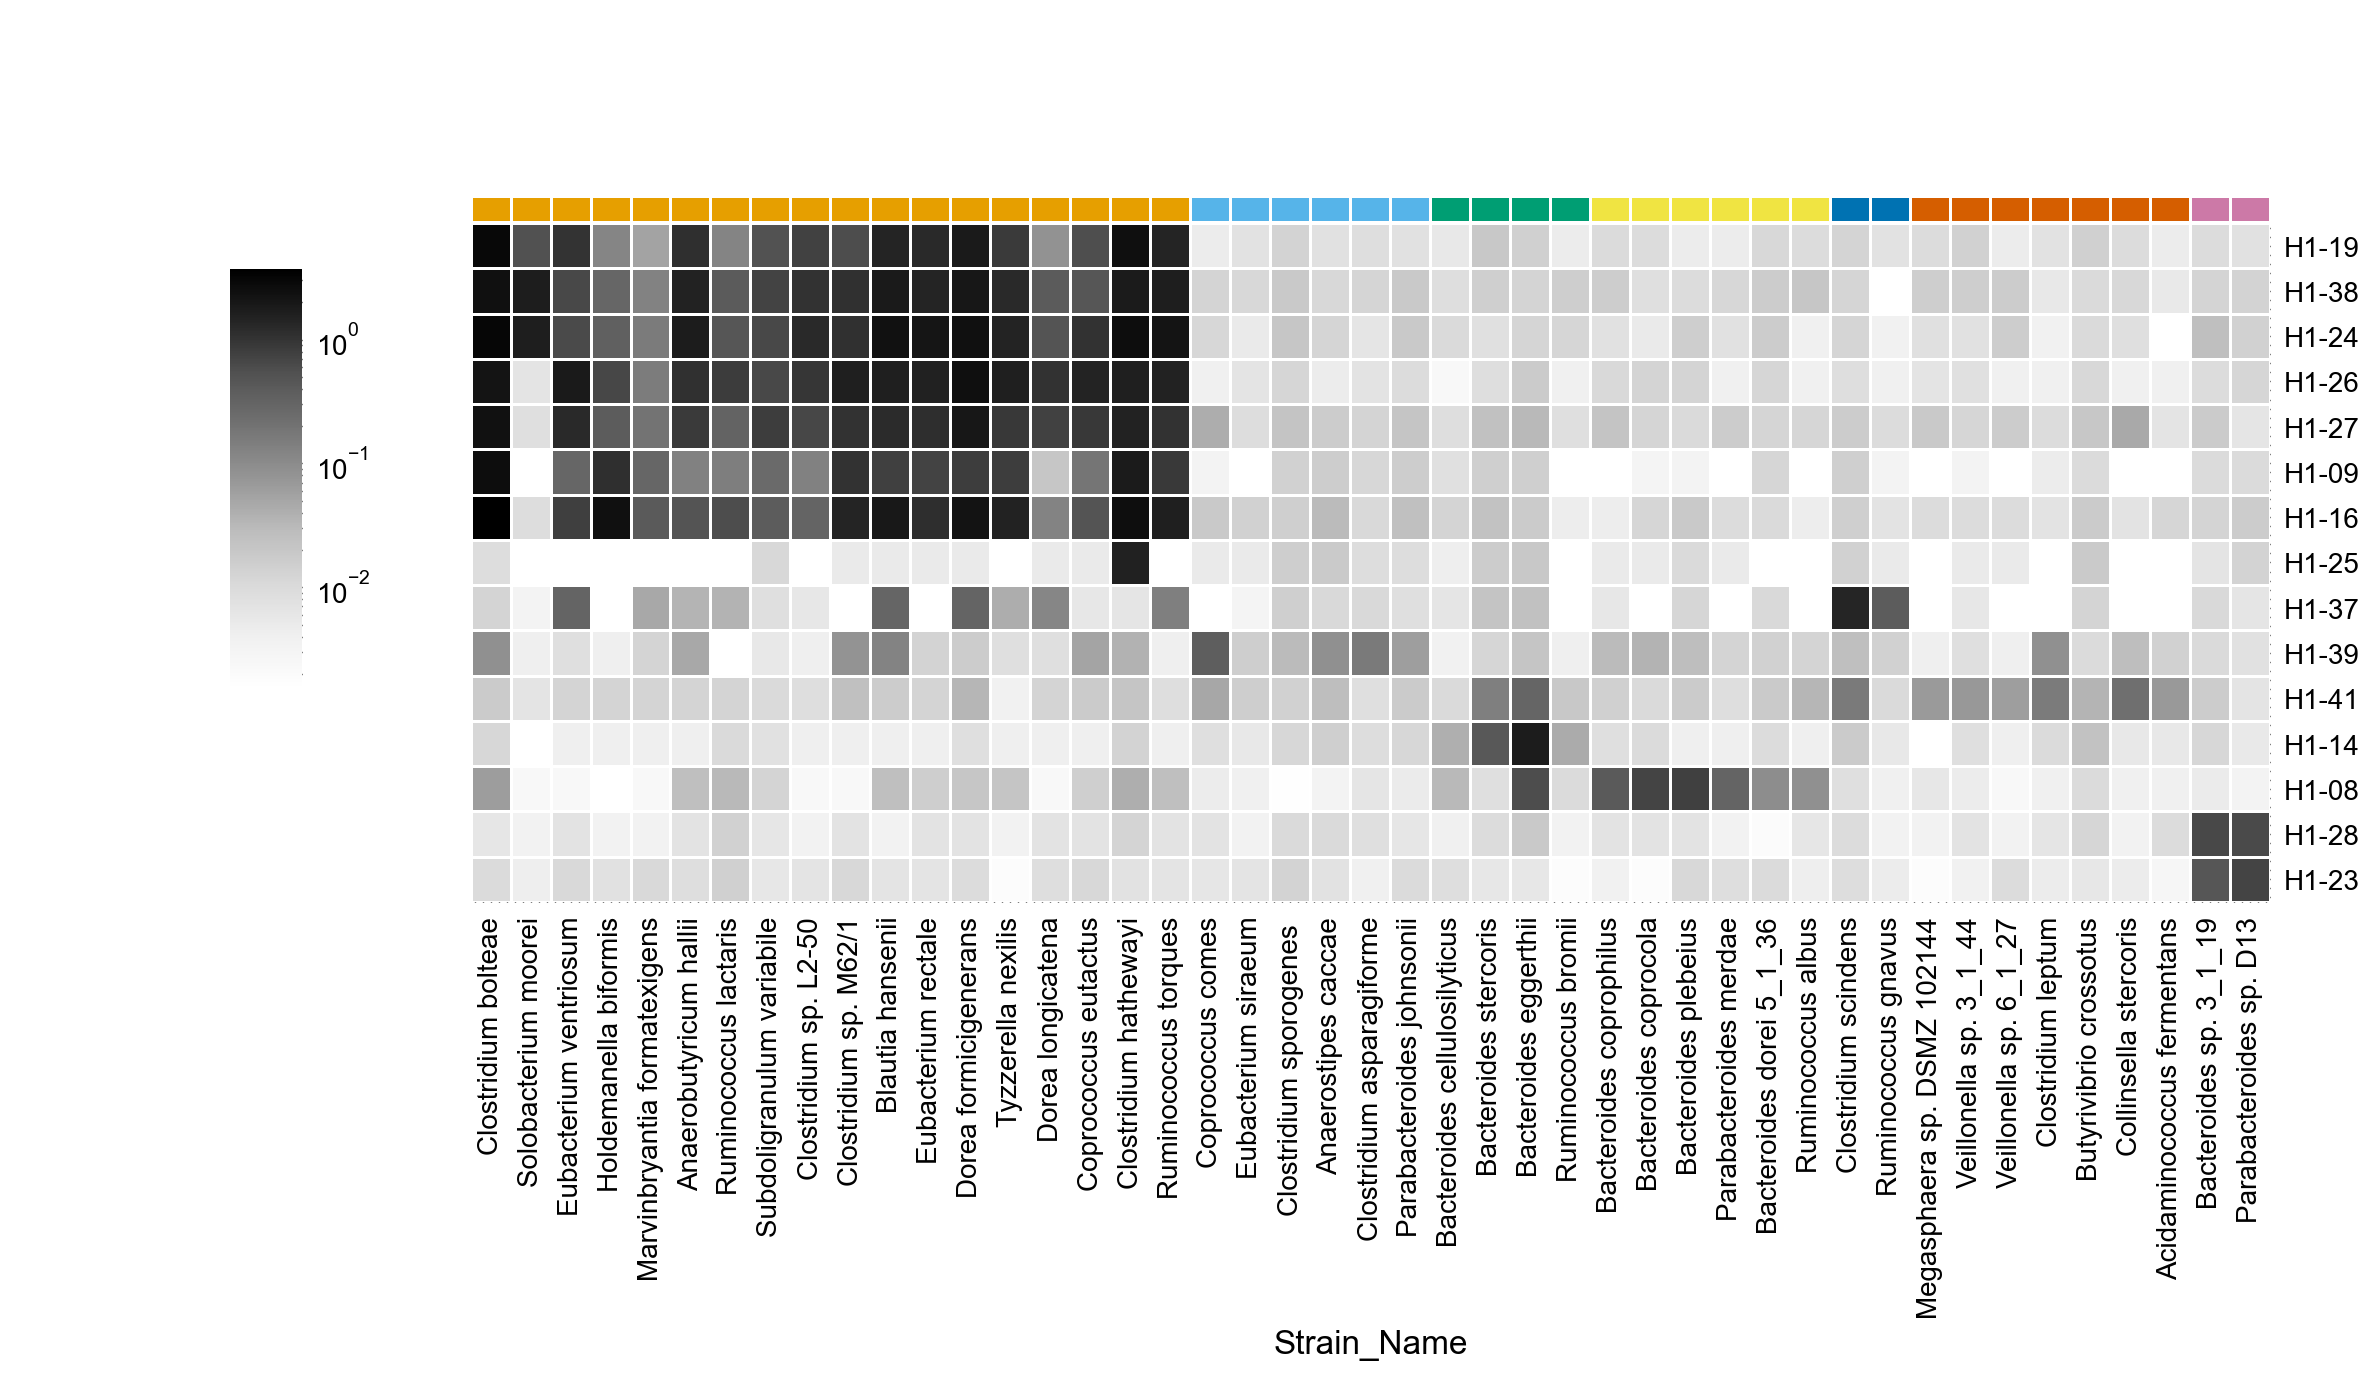

In [24]:
receptor_bind_vars = ['H1-19','H1-38','H1-24','H1-26','H1-27','H1-09','H1-16',
            'H1-25',
            'H1-37','H1-39', # 'H1-33','H1-34', bind food
            'H1-41','H1-14','H1-08',
            'H1-28',
            'H1-23']

cross_reac_fig_data = cross_reactivity_data.loc[cross_reactivity_data.strain_id.notna()].merge(full_data_w_clusters[['strain_id','imm_resp_flag', 'sig_imm_resp_flag', 'cross_reactivity_cluster']].groupby('strain_id').mean(), 
                                                                                                    how = 'left', on = 'strain_id', validate = 'one_to_one').sort_values(by='cross_reactivity_cluster', 
                                                                                                                            ascending= True).set_index('Strain_Name')
cross_reac_fig_data.loc[:,'mean_sigma'] = cross_reac_fig_data[receptor_bind_vars].mean(axis = 1)

hybridoma_abundance_data.loc[:, "total_Treg"] = np.sum(hybridoma_abundance_data[['pTreg','tTreg']].values, axis = 1)
hybridoma_abundance_data.loc[:, "total_effector"] = np.sum(hybridoma_abundance_data[['Th1','Th2', 'Th17', 'Other Effector Th', 'Memory', 'Fr4 Th']].values, axis = 1)

hybridoma_cluster_data = cross_reac_fig_data[['cross_reactivity_cluster', 'strain_id'] + receptor_bind_vars] #.groupby('cross_reactivity_cluster', as_index = False).mean()
hybridoma_cluster_data.loc[:,'total_Treg'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].total_Treg.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'total_effector'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].total_effector.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Th1'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].Th1.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Th2'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].Th2.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Th17'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].Th17.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Other Effector Th'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var]['Other Effector Th'].item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Memory'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].Memory.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'Fr4 Th'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var]['Fr4 Th'].item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'pTreg'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].pTreg.item() for var in receptor_bind_vars], axis = 0)
hybridoma_cluster_data.loc[:,'tTreg'] = np.max([hybridoma_cluster_data[var].values*hybridoma_abundance_data.loc[hybridoma_abundance_data.Hybridoma == var].tTreg.item() for var in receptor_bind_vars], axis = 0)


plot_data = cross_reac_fig_data[receptor_bind_vars]

lut = {0: ito_colors[0], 1: ito_colors[1], 2: ito_colors[2], 3: ito_colors[3], 4: ito_colors[4], 5: ito_colors[5], 6: ito_colors[6], 7: ito_colors[7], 8: ito_colors[8]}
col_colors = cross_reac_fig_data['cross_reactivity_cluster'].map(lut)
ax = sns.clustermap(plot_data.transpose(), col_colors=col_colors.values, row_cluster=False, col_cluster=False,
              norm=mpl.colors.LogNorm(), cmap='Greys', fmt=".2f", linewidths=.5,
              cbar_pos=(0.1, .5, .03, .3), figsize=(12, 7))

# The 'fig' object is accessible via the .figure attribute
fig = ax.figure

plt.show()

# To save the figure, use the savefig method of the ClusterGrid object to avoid clipping
ax.savefig('_figs/fig_receptor_clusters'+'.pdf', dpi=300, bbox_inches='tight')

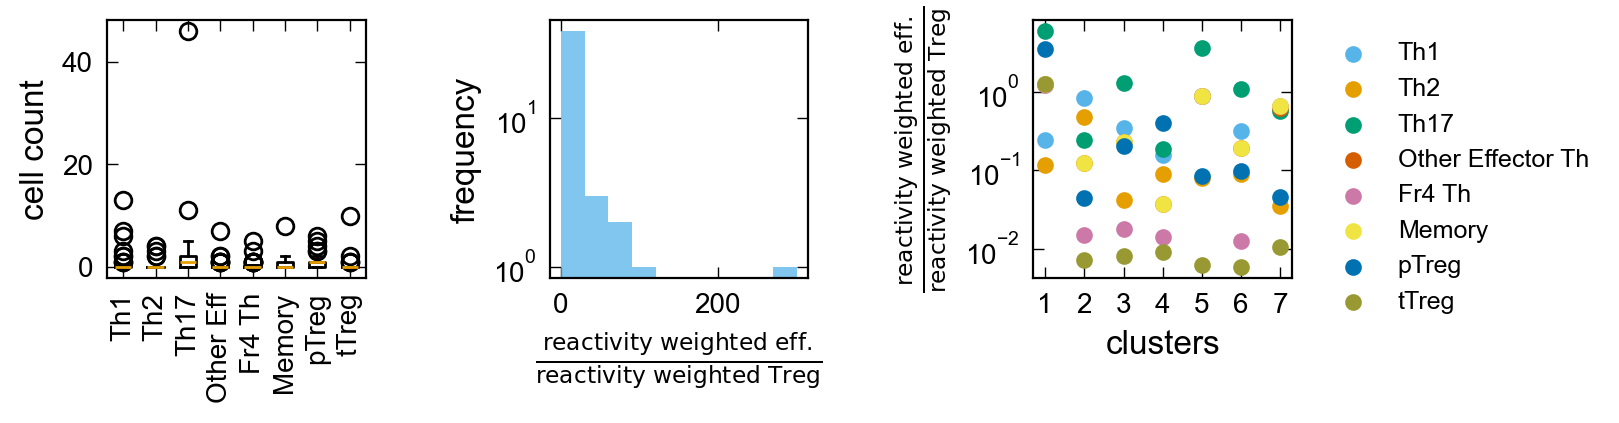

In [25]:
# Plot figures
fig, axs = plt.subplots(1, 3, figsize=(8.0, 2.0), sharex = False, constrained_layout=True)
          
var_list = ['Th1','Th2', 'Th17', 'Other Effector Th', 'Fr4 Th', 'Memory', 'pTreg', 'tTreg']
var_labels = ['Th1','Th2', 'Th17', 'Other Eff', 'Fr4 Th', 'Memory', 'pTreg', 'tTreg']

for_figc = hybridoma_cluster_data.drop('strain_id', axis=1).groupby('cross_reactivity_cluster', as_index = False).mean()

axs[0].boxplot(hybridoma_abundance_data[var_list], tick_labels= var_labels)
axs[0].set_ylabel('cell count', fontsize = 12)
axs[0].xaxis.set_tick_params(labeltop=False, rotation = 90)

for var in var_list:
    axs[2].scatter(for_figc.cross_reactivity_cluster, for_figc[var], label = var)

axs[1].hist(hybridoma_cluster_data['total_effector']/hybridoma_cluster_data['total_Treg'], bins = 10, log = True, alpha = 0.75);
axs[1].set_xlabel(r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$', fontsize = 12)
axs[1].set_ylabel('frequency', fontsize = 12)
axs[2].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
axs[2].set_ylabel(r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$', fontsize = 12)
axs[2].semilogy()
axs[2].set_xticks(for_figc.cross_reactivity_cluster)
axs[2].set_xlabel('clusters', fontsize = 12)

for j, ax in enumerate(axs.flat):
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_hybridoma_cell_count_by_type'+'.pdf', dpi=300, bbox_inches='tight')

/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/558625345.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/558625345.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
/var/folders/_q/50__mrnj2zv6hb8crhk3q46m0000gn/T/ipykernel_35890/558625345.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)


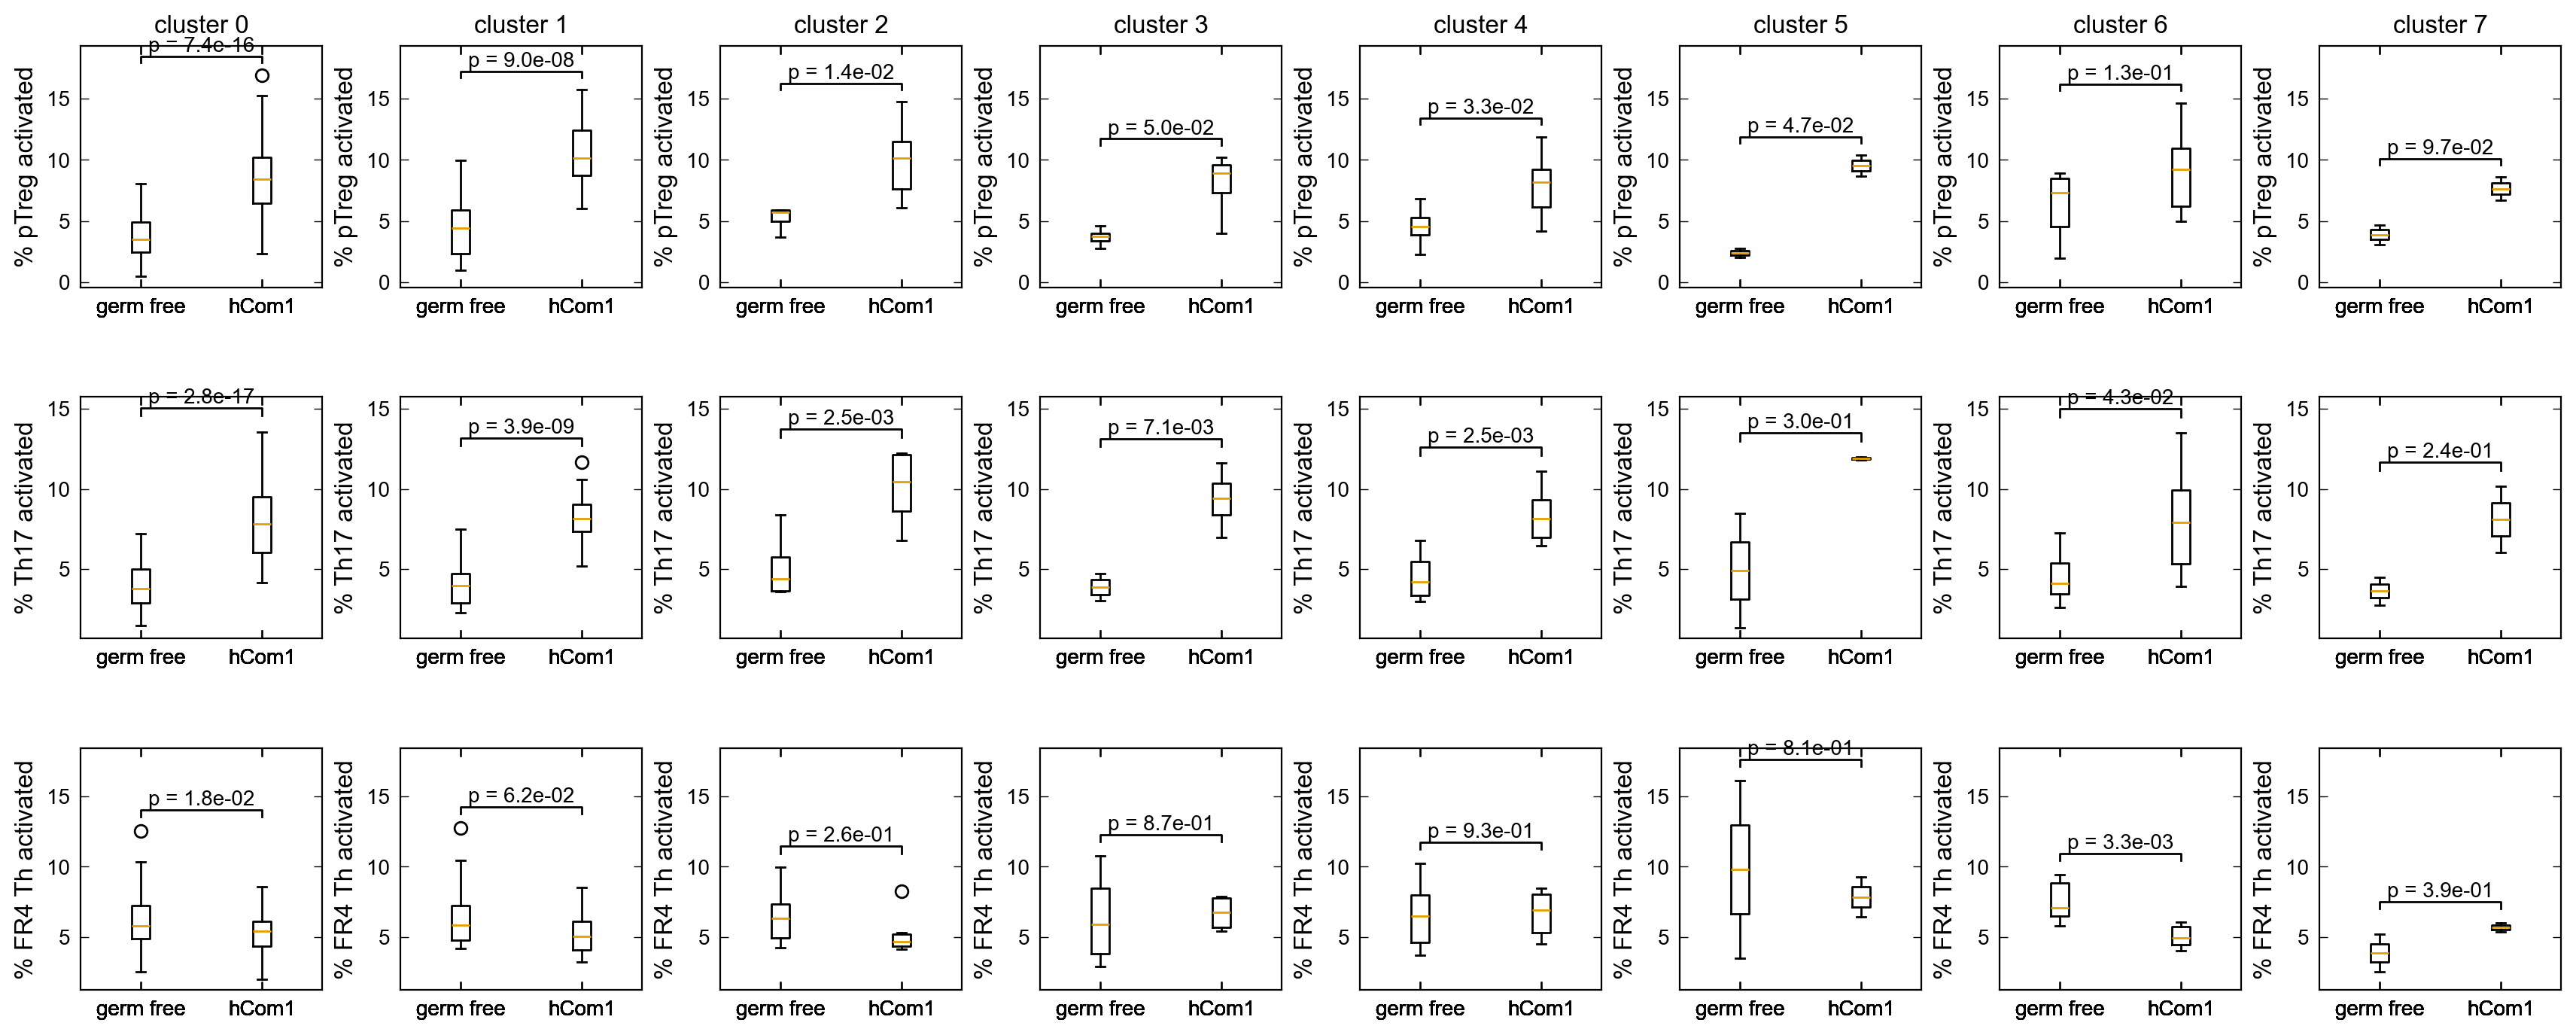

In [26]:
# Plot figures
fig, axs = plt.subplots(3, 8, figsize=(17.0, 7.0), sharex = 'row', sharey = 'row', constrained_layout=True)

coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
var_list = [['GF_pTreg_Average', 'hCom1d_pTreg_Average'], 
                      ['GF_Th17_Average', 'hCom1d_Th17_Average'], 
                      ['GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']]

data = full_data_w_clusters[['Name', 'cross_reactivity_cluster'] + coverage_variables].groupby(['Name', 'cross_reactivity_cluster'], as_index = False).mean()

for i, var in enumerate(var_list):
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = int(g['cross_reactivity_cluster'].values[0])
        # mean_g = g.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
        GF_pop, hcom1_pop = g[var[0]], g[var[1]]
        # axs[i, cluster].hist(GF_pop, bins = 10, label = 'germ free');
        # axs[i, cluster].hist(hcom1_pop, bins = 10, label = 'hCom1d');
        axs[i, cluster].boxplot([GF_pop, hcom1_pop], tick_labels=['germ free', 'hCom1'])
        # axs[i, cluster].axvline(x = np.mean(GF_pop), color = 'blue')
        # axs[i, cluster].axvline(x = np.mean(hcom1_pop), color = 'red')
        if i == 0:
            axs[i, cluster].set_title('cluster '+str(int(cluster)), fontsize = 12) 

        if cluster == 0:
            axs[i, cluster].legend(fontsize=9, loc = 'upper right', framealpha=0)
        
        axs[i, cluster].set_ylabel(['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][i], fontsize = 12)
            

        # Run two-sided Mann-Whitney test with null that the two distribitions are identical
        tind_stat, p_value = ttest_ind(GF_pop, hcom1_pop, equal_var=False)
        x1, x2 = 1, 2   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
        y, h, col = np.amax(np.array([GF_pop, hcom1_pop])) + 1, 0.5, 'k'
        axs[i, cluster].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c=col)
        axs[i, cluster].text((x1+x2)*.5, y+h, f'p = {p_value:.1e}', ha='center', va='bottom', color=col)
        #axs[i, cluster].text((x1 + x2) * 0.5, y + h, f'p = {p:.3e}', ha='center', va='bottom', color='k')
        # print(p)

        axs[i, cluster].set_box_aspect(1)
        axs[i, cluster].minorticks_off()
        axs[i, cluster].tick_params(axis='both', which='major', labelsize=10)
        axs[i, cluster].xaxis.set_tick_params(labeltop=False)
        axs[i, cluster].yaxis.set_tick_params(labelleft=True)

# fig.savefig('_figs/fig_immune_activation_GF_hcom1'+'.pdf', dpi=300, bbox_inches='tight')

In [27]:
# sns.pairplot(hybridoma_cluster_data.groupby('cross_reactivity_cluster', as_index = False).mean(), vars=['total_Treg', 'Th1','Th2', 'Th17', 'Other Effector Th','Memory', 'Fr4 Th'])

In [28]:
# # Plot figures
# coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
#                       'GF_Th17_Average', 'hCom1d_Th17_Average', 
#                       'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
# cluster_variables= ['Phyla','strain_drop_cluster','amino_drop_cluster','cross_reactivity_cluster']
# var_list = ['day0_abundance_batch1',
#             'Batch1_week1_m1', 'Batch1_week1_m2', 'Batch1_week1_m3', 'Batch1_week1_m4', 'Batch1_week1_m5', 
#             'Batch1_week2_m1', 'Batch1_week2_m2', 'Batch1_week2_m3', 'Batch1_week2_m4', 'Batch1_week2_m5',
#             'Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 'Batch1_week3_m4', 'Batch1_week3_m5', 
#             'Batch1_week4_m1', 'Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4', 'Batch1_week4_m5']

# fig, axs = plt.subplots(2, 4, figsize=(17.0, 6.0), sharex = False, constrained_layout=True)

# for i, custer_var in enumerate(cluster_variables):
#     data = full_data_w_clusters[var_list + coverage_variables + [cluster_variables[i]]].groupby(cluster_variables[i], as_index = False).sum()

#     # Compute mean abundance
#     data[var_list] = data[var_list].apply(alr_transform, axis=0)
#     data.loc[:, 'wk1_mean_abundance'] = np.mean(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
#                                                                                  'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
#     data.loc[:, 'wk2_mean_abundance'] = np.mean(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
#                                                                                  'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
#     data.loc[:, 'wk3_mean_abundance'] = np.mean(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
#                                                                                  'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
#     data.loc[:, 'wk4_mean_abundance'] = np.mean(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
#                                                                                  'Batch1_week4_m5']], axis = 1)
    
#     # Compute standard deviation of abundance
#     data.loc[:, 'wk0_std_abundance'] = 0*np.std(data.day0_abundance_batch1)
#     data.loc[:, 'wk1_std_abundance'] = np.std(data[['Batch1_week1_m1','Batch1_week1_m2', 'Batch1_week1_m3', 
#                                                                                  'Batch1_week1_m4','Batch1_week1_m5']], axis = 1)
#     data.loc[:, 'wk2_std_abundance'] = np.std(data[['Batch1_week2_m1', 'Batch1_week2_m2','Batch1_week2_m3', 
#                                                                                  'Batch1_week2_m4', 'Batch1_week2_m5']], axis = 1)
#     data.loc[:, 'wk3_std_abundance'] = np.std(data[['Batch1_week3_m1', 'Batch1_week3_m2', 'Batch1_week3_m3', 
#                                                                                  'Batch1_week3_m4', 'Batch1_week3_m5']], axis = 1)
#     data.loc[:, 'wk4_std_abundance'] = np.std(data[['Batch1_week4_m1','Batch1_week4_m2', 'Batch1_week4_m3', 'Batch1_week4_m4',
#                                                                                  'Batch1_week4_m5']], axis = 1)

#     mean_array = data[[cluster_variables[i], 'day0_abundance_batch1', 'wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].values
#     std_array = data[[cluster_variables[i], 'wk0_std_abundance','wk1_std_abundance', 'wk2_std_abundance','wk3_std_abundance','wk4_std_abundance']].values
#     x_data = np.array([0, 1, 2, 3, 4])
    
#     for k, y in enumerate(mean_array):
#         axs[0,i].errorbar(x_data, y[1:],
#                     yerr = std_array[k,1:],elinewidth = 1.0,linewidth = 1.5,fmt = '-o', color = ito_colors[k], 
#                           label = int(y[0]) if i > 0 else y[0])

#     for_analysis = data
#     for_analysis.loc[:, 'max_abundance'] = np.amax(for_analysis[['wk1_mean_abundance', 'wk2_mean_abundance']], axis = 1)
#     for_analysis.loc[:, 'del_abundance'] = for_analysis['wk3_mean_abundance'] - for_analysis['max_abundance']
#     # for_analysis.loc[:, 'del_abundance'] = 10**(-(for_analysis['wk3_mean_abundance'] - for_analysis['wk2_mean_abundance'])) #- 1
#     for_analysis.loc[:, 'del_pTreg'] = for_analysis['hCom1d_pTreg_Average'] - for_analysis['GF_pTreg_Average']
#     for_analysis.loc[:, 'del_Th17'] = for_analysis['hCom1d_Th17_Average'] - for_analysis['GF_Th17_Average']
#     for_analysis.loc[:, 'del_FR4_Th'] = for_analysis['hCom1d_FR4_Th_Average'] - for_analysis['GF_FR4_Th_Average']
#     for_analysis.loc[:, 'ratio_pTreg'] = np.log10(for_analysis['hCom1d_pTreg_Average']/for_analysis['GF_pTreg_Average'])
#     for_analysis.loc[:, 'ratio_Th17'] = np.log10(for_analysis['hCom1d_Th17_Average']/for_analysis['GF_Th17_Average'])
#     for_analysis.loc[:, 'ratio_FR4_Th'] = np.log10(for_analysis['hCom1d_FR4_Th_Average']/for_analysis['GF_FR4_Th_Average'])
#     for_analysis.loc[:, 'diff_Th17_pTreg'] = for_analysis['del_Th17'] - for_analysis['del_pTreg']
#     for_analysis.loc[:, 'ratio_Th17_pTreg'] = np.log10(for_analysis['del_Th17']/for_analysis['del_pTreg'])
#     for_analysis.loc[:, 'ratio_FR4_Th_pTreg'] = np.log10(for_analysis['del_FR4_Th']/for_analysis['del_pTreg'])

#     x_data = for_analysis.max_abundance.values[1:]
#     y_data = for_analysis.del_abundance.values[1:]

#     if i < 3:
#         mask = ~np.isnan(x_data) & ~np.isinf(x_data) & ~np.isnan(y_data) & ~np.isinf(y_data)
#     else:
#         mask = ~np.isnan(x_data) & ~np.isinf(x_data) & ~np.isnan(y_data) & ~np.isinf(y_data) & (y_data <= 0)
#     if np.sum(mask) >= 2:
#         # reg = LinearRegression().fit(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
#         # r_sq = reg.score(x_data[mask].reshape(-1, 1), y_data[mask]) #, sample_weight = z_data)
#         # m = reg.coef_[0]
#         # b = reg.intercept_
#         m, b, r_value, p_value, std_err = scipy.stats.linregress(x_data[mask], y_data[mask])
#         axs[1,i].plot(np.unique(x_data[mask]), 
#                 m*np.unique(x_data[mask]) + b, 
#                       color = 'black',
#                       zorder = 0,
#                       linewidth = 1.5,
#                 label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ r', $m$: ' + str("{:.2f}".format(m))+ r', $p$: ' + str("{:.2f}".format(p_value)))

#     axs[1,i].scatter(x_data[mask], y_data[mask], s = 20, color = np.array(ito_colors[1:1+len(x_data)])[mask])
    
# for j, ax in enumerate(axs.flat):
#     # ax.set_yscale('symlog', linthresh=1.)

#     if j < len(cluster_variables):
#         ax.set_xlabel('week', fontsize = 14)
#         ax.set_ylabel(r'$\log_{10}([\text{abundance ratio}])$', fontsize = 14)
#         ax.set_title(cluster_variables[j], fontsize = 14)
#         ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=11, framealpha=0)
#     else:
#         ax.set_xlabel(r'max $\log_{10}([\text{abundance ratio}])$', fontsize = 14)
#         ax.set_ylabel(r'$\Delta$'+r'$\log_{10}([\text{abundance ratio}])$', fontsize = 14)
#         ax.legend(fontsize=11, framealpha=0)
        
#     ax.set_box_aspect(1)
#     ax.minorticks_off()
#     ax.tick_params(axis='both', which='major', labelsize=10)
#     ax.xaxis.set_tick_params(labeltop=False)

# fig.savefig('_figs/fig_dynamics_by_cluster'+'.pdf', dpi=300, bbox_inches='tight')

In [48]:
# Create ALR datasets
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'
var_list = ['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']
additional_day0_vars = ['day0_abundance_batch2', 'day0_abundance_batch3']
additional_wk2_vars = ['day14_abundance']
additional_wk4_vars = ['Batch2_week4_m1', 'Batch2_week4_m2', 'Batch2_week4_m3',
                       'Batch3_week4_m1', 'Batch3_week4_m2', 'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5']

additional_abundance_vars = additional_day0_vars + additional_wk2_vars + additional_wk4_vars
replicate_num = 5

# Prepare cluster level data
cluster_abundance_data = full_data_w_clusters[var_list + [cluster_variable, 'replicate'] + additional_abundance_vars].groupby([cluster_variable, 'replicate'], as_index = False).sum()
cluster_abundance_data.loc[:, 'Batch1_peak'] = np.amax(cluster_abundance_data[['Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']], axis = 1)
cluster_alr_list = []
for (_, g) in cluster_abundance_data.groupby(['replicate'], sort = False):
    df = g.reset_index()
    df.loc[:,['day0_alr', 'wk1_alr', 'wk2_alr', 'wk3_alr', 'wk4_alr']] = df[['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']].apply(alr_transform, axis=0).values
    cluster_alr_list.append(df)

cluster_alr_data = pd.concat(cluster_alr_list).reset_index(drop = True).replace([np.inf, -np.inf], np.nan)
cluster_alr_data.loc[:, 'peak_1_2_alr'] = np.amax(cluster_alr_data[['wk1_alr', 'wk2_alr']], axis = 1)
cluster_alr_data.loc[:, 'peak_alr'] = np.amax(cluster_alr_data[['wk1_alr', 'wk2_alr', 'wk3_alr', 'wk4_alr']], axis = 1)

# Prepare strain level data
strain_abundance_data = pd.concat([cluster_abundance_data.head(replicate_num),
                         full_data_w_clusters[var_list + [cluster_variable, 'replicate'] + additional_abundance_vars]]).reset_index(drop = True)
strain_abundance_data.loc[:,'strain_id'] = np.array(replicate_num*['nonimmunogenic_cluster'] + full_data_w_clusters.strain_id.tolist())
strain_abundance_data.loc[:, 'Batch1_peak'] = np.amax(strain_abundance_data[['Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']], axis = 1)

strain_alr_list = []
for (_, g) in strain_abundance_data.groupby(['replicate'], sort = False):
    df = g.reset_index()
    df.loc[:,['day0_alr', 'wk1_alr', 'wk2_alr', 'wk3_alr', 'wk4_alr']] = df[['day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3', 'Batch1_week4']].apply(alr_transform, axis=0).values
    strain_alr_list.append(df)

strain_alr_data = pd.concat(strain_alr_list).reset_index(drop = True).replace([np.inf, -np.inf], np.nan)
strain_alr_data.loc[:, 'peak_1_2_alr'] = np.amax(strain_alr_data[['wk1_alr', 'wk2_alr']], axis = 1)
strain_alr_data.loc[:, 'peak_alr'] = np.amax(strain_alr_data[['wk1_alr', 'wk2_alr', 'wk3_alr', 'wk4_alr']], axis = 1)

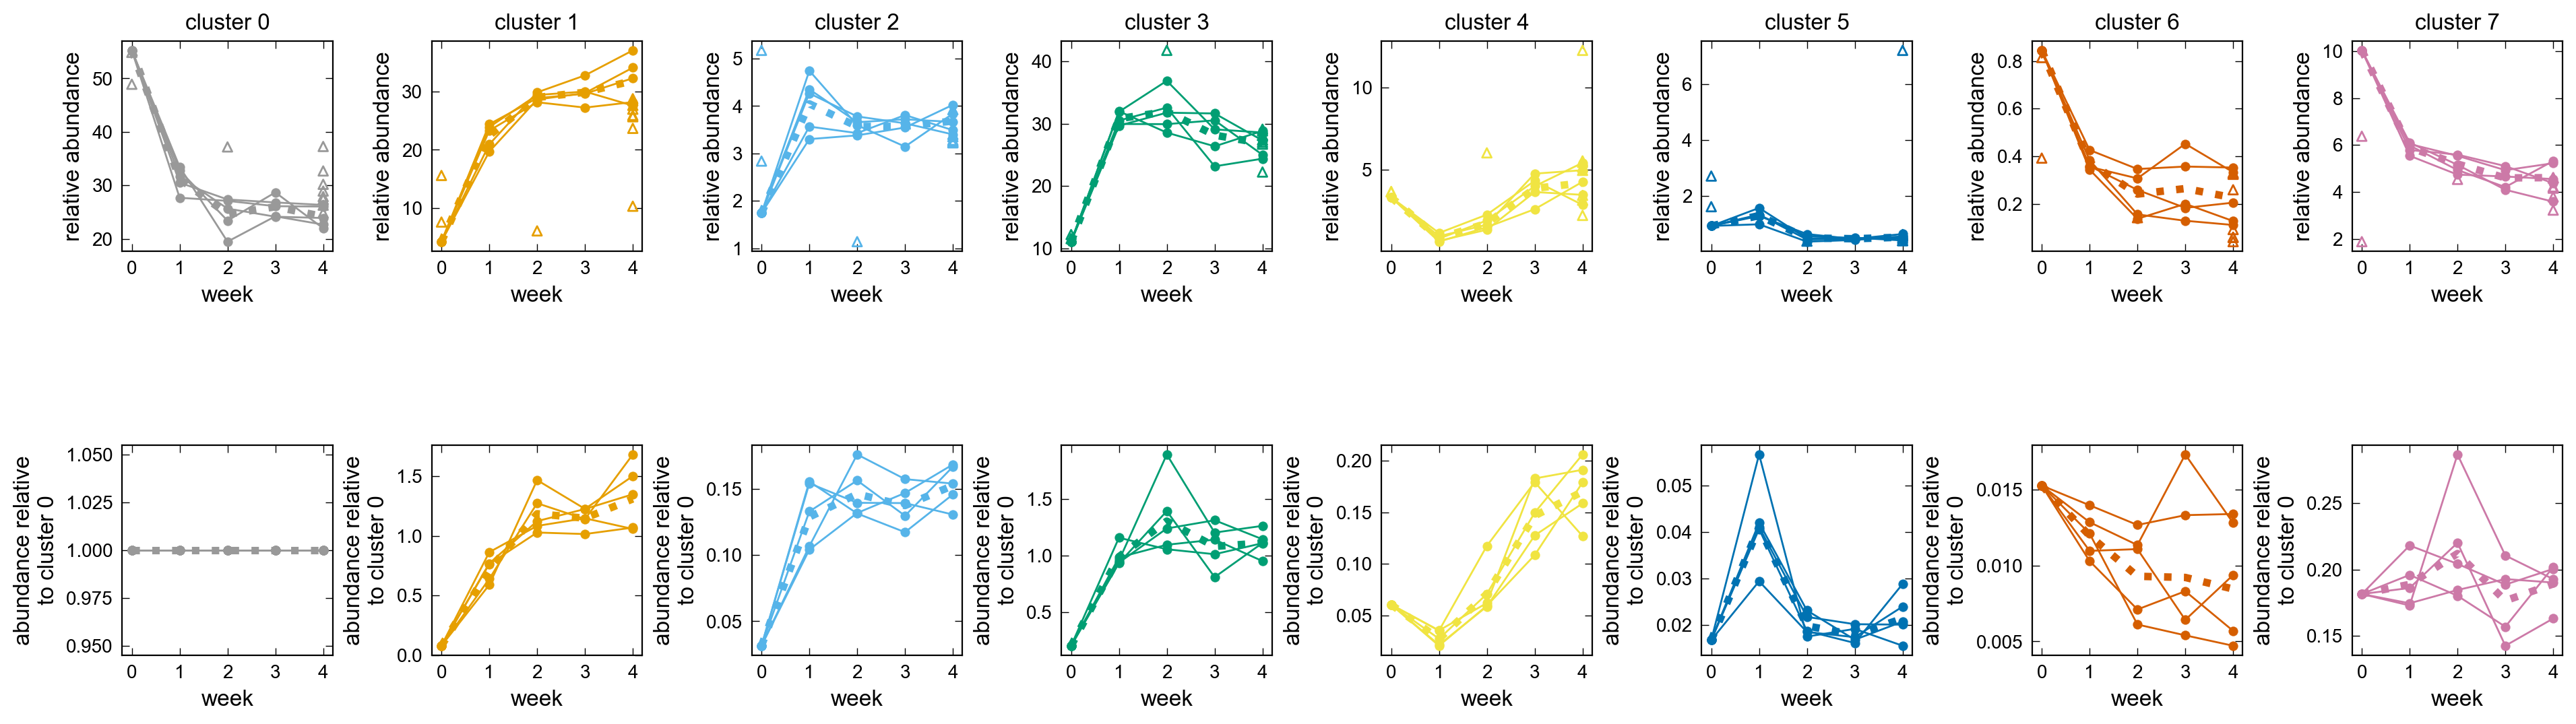

In [30]:
fig, axs = plt.subplots(2, 8, figsize=(19.0, 6.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
alr_var_list = ["day0_alr", "wk1_alr", "wk2_alr", "wk3_alr", "wk4_alr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

data = cluster_alr_data

for (_, g) in data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    mean_g = g.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    axs[0, int(cluster)].set_title('cluster '+str(int(cluster)), fontsize = 12) 
    axs[0, int(cluster)].plot(mean_g[abundance_var_list].values.T, color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[0, int(cluster)].plot(g[abundance_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[0, int(cluster)].scatter(len(additional_wk4_vars)*[4], mean_g[additional_wk4_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].scatter(len(additional_wk2_vars)*[2], mean_g[additional_wk2_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].scatter(len(additional_day0_vars)*[0], mean_g[additional_day0_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].set_ylabel('relative abundance', fontsize = 12)
    
    axs[1, int(cluster)].plot(10**np.mean(g[alr_var_list].values.T, axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[1, int(cluster)].plot(10**g[alr_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[1, int(cluster)].set_ylabel('abundance relative\nto cluster 0', fontsize = 12)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

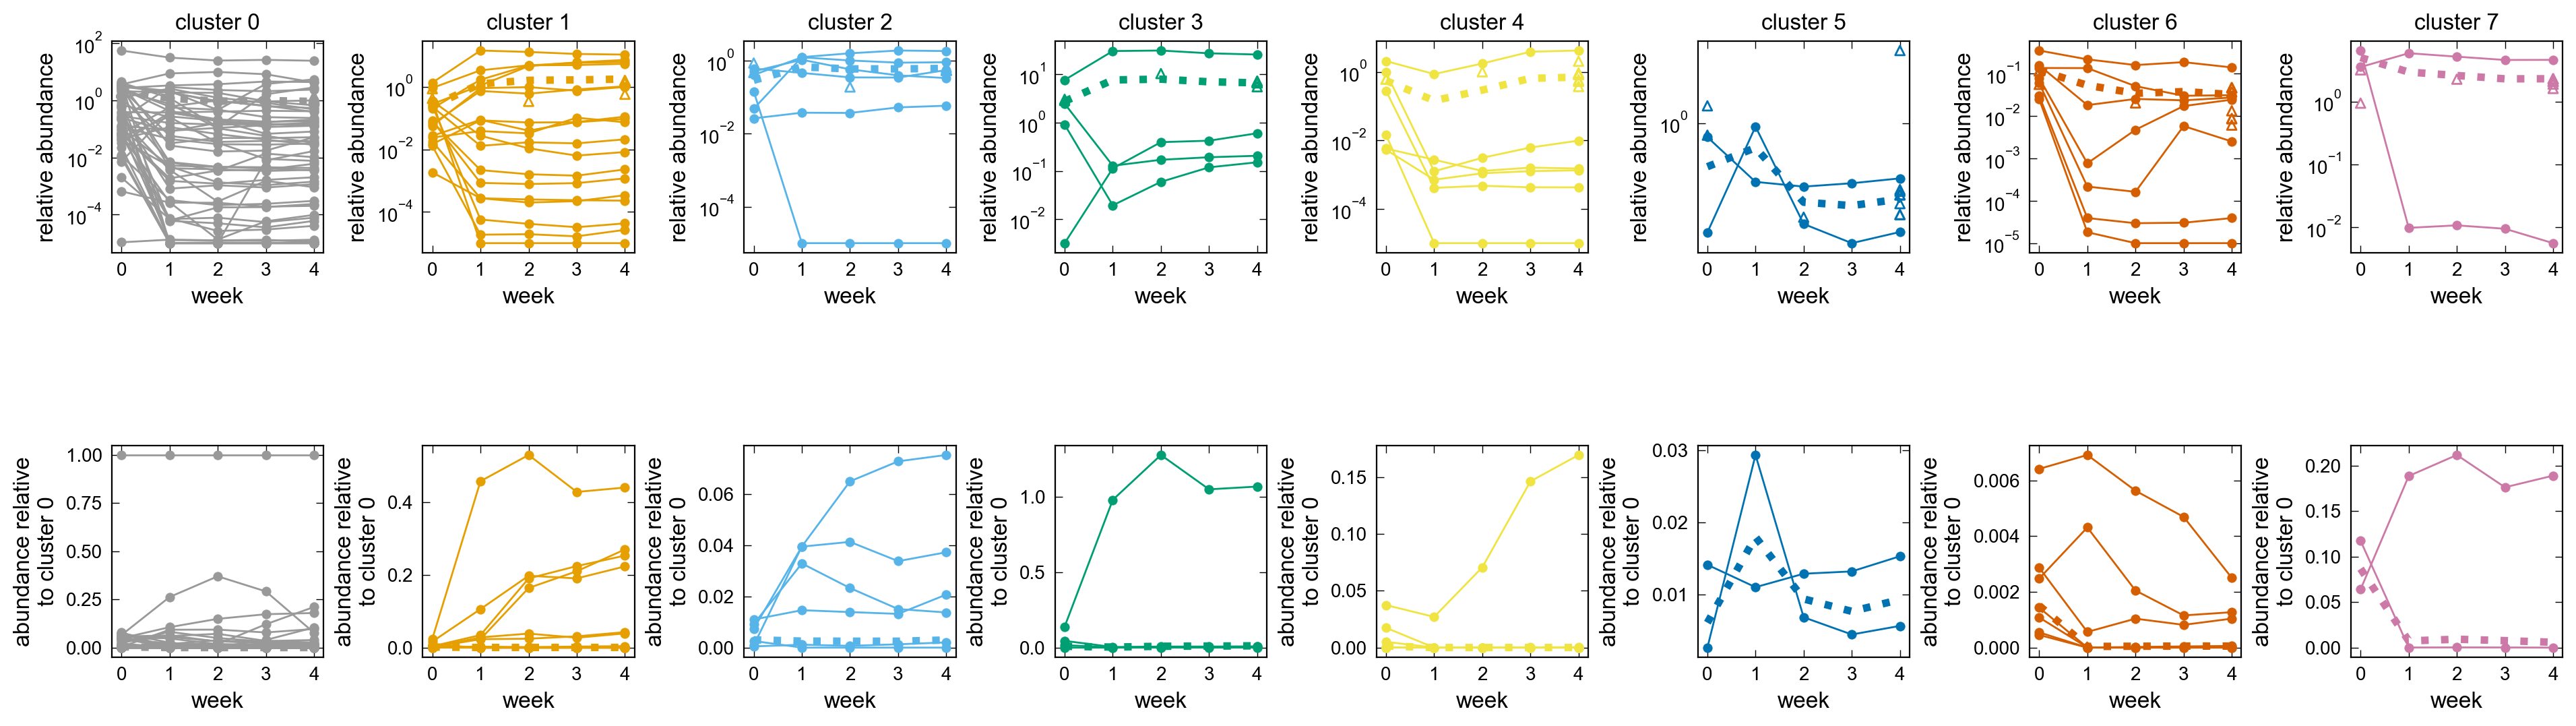

In [31]:
fig, axs = plt.subplots(2, 8, figsize=(19.0, 6.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
alr_var_list = ["day0_alr", "wk1_alr", "wk2_alr", "wk3_alr", "wk4_alr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

data = strain_alr_data.drop('replicate',axis = 1).groupby('strain_id', as_index = False).mean()

for (_, g) in data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    mean_g = g.drop('strain_id', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    axs[0, int(cluster)].set_title('cluster '+str(int(cluster)), fontsize = 12) 
    axs[0, int(cluster)].plot(mean_g[abundance_var_list].values.T, color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[0, int(cluster)].plot(g[abundance_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[0, int(cluster)].scatter(len(additional_wk4_vars)*[4], mean_g[additional_wk4_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].scatter(len(additional_wk2_vars)*[2], mean_g[additional_wk2_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].scatter(len(additional_day0_vars)*[0], mean_g[additional_day0_vars].values.T.ravel(), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], marker = '^', facecolor = 'none')
    axs[0, int(cluster)].semilogy()
    axs[0, int(cluster)].set_ylabel('relative abundance', fontsize = 12)
    
    axs[1, int(cluster)].plot(10**np.mean(g[alr_var_list].values.T, axis = 1), color = g['cross_reactivity_cluster'].map(lut).tolist()[0], linewidth = 4.0, linestyle = ':')
    axs[1, int(cluster)].plot(10**g[alr_var_list].values.T, marker = 'o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0])
    axs[1, int(cluster)].set_ylabel('abundance relative\nto cluster 0', fontsize = 12)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

ruminococcus gnavus in cluster 5 is a known inflammatory bacteria and it's abundance shows a decline.

In [32]:
strain_alr_data.loc[:,'diff'] = strain_alr_data['Batch1_week4']/strain_alr_data['Batch1_week1']
strain_alr_data.sort_values(by=['diff', 'strain_id'], ascending= True)

,index,cross_reactivity_cluster,replicate,day0_abundance_batch1,Batch1_week1,Batch1_week2,Batch1_week3,Batch1_week4,day0_abundance_batch2,day0_abundance_batch3,...,Batch1_peak,strain_id,day0_alr,wk1_alr,wk2_alr,wk3_alr,wk4_alr,peak_1_2_alr,peak_alr,diff
169,172,0.0,m2,0.215459,0.007383,0.000320,0.000033,0.000039,0.222108,0.106563,...,0.007383,lactobacillus ruminis atcc 25644,-2.408895,-3.633294,-4.904349,-5.867203,-5.786548,-3.633294,-3.633294,0.005296
423,423,0.0,m5,0.698210,0.433996,0.051330,0.010493,0.003262,0.428943,0.180528,...,0.433996,bifidobacterium adolescentis l2-32,-1.898274,-1.804955,-2.722895,-3.396105,-3.902424,-1.804955,-1.804955,0.007516
238,240,0.0,m3,0.007229,0.458486,0.388328,0.003932,0.004714,0.033759,0.147439,...,0.458486,intestinibacter bartlettii dsm 16795,-3.883178,-1.854177,-1.780438,-3.863367,-3.668938,-1.780438,-1.780438,0.010282
327,328,0.0,m4,0.060099,0.000709,0.000010,0.000010,0.000010,0.070487,0.082669,...,0.000709,bifidobacterium catenulatum dsm 16992,-2.963393,-4.633986,-6.437404,-6.428528,-6.420848,-4.633986,-4.633986,0.014104
194,197,6.0,m2,0.354381,0.264734,0.069159,0.023866,0.003741,0.172050,0.027603,...,0.264734,veillonella sp. 3_1_44,-2.192789,-2.078705,-2.569652,-3.005305,-3.805779,-2.078705,-2.078705,0.014130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,295,6.0,m3,0.059853,0.000134,0.000173,0.027898,0.011632,0.042008,0.013348,...,0.000173,veillonella sp. 6_1_27,-2.965171,-5.388399,-5.131590,-3.012369,-3.276685,-5.131590,-3.012369,86.803358
288,290,0.0,m3,0.010413,0.000010,0.000010,0.000236,0.007828,0.005841,0.011909,...,0.000010,slackia heliotrinireducens dsm 20476,-3.724688,-6.515504,-6.369637,-5.085032,-3.448672,-6.369637,-3.448672,782.807000
197,199,6.0,m3,0.079298,0.000024,0.006028,0.026269,0.032275,0.082888,0.068022,...,0.006028,acidaminococcus fermentans dsm 20731,-2.843000,-6.133486,-3.589438,-3.038500,-2.833459,-3.589438,-2.833459,1339.216598
190,193,0.0,m2,0.010413,0.000010,0.000010,0.038886,0.024367,0.005841,0.011909,...,0.000010,slackia heliotrinireducens dsm 20476,-3.724688,-6.501515,-6.409499,-2.793280,-2.991915,-6.409499,-2.793280,2436.743000


Abundance ratio seems to obscure signals compared to the relative abundance

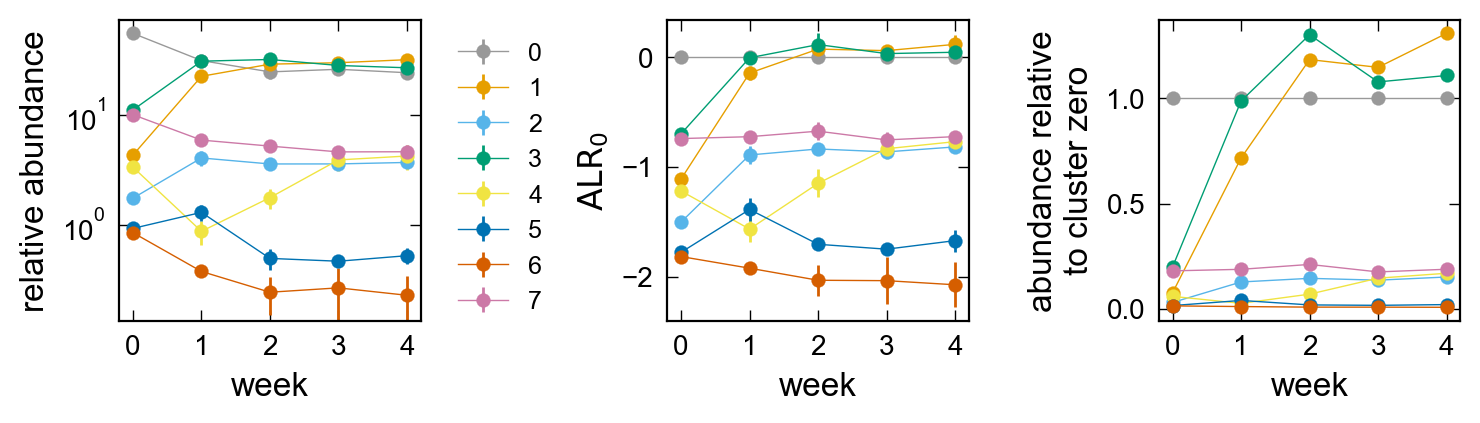

In [33]:
fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.0), sharex = False, constrained_layout=True)

alr_var_list = ["day0_alr", "wk1_alr", "wk2_alr", "wk3_alr", "wk4_alr"]
abundance_var_list = ["day0_abundance_batch1", "Batch1_week1", "Batch1_week2", "Batch1_week3", "Batch1_week4"]

mean_data = cluster_alr_data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
std_data = cluster_alr_data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()

for (_, g) in mean_data.groupby('cross_reactivity_cluster'):
    cluster = g['cross_reactivity_cluster'].values[0]
    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, abundance_var_list].values
    axs[0].errorbar(np.arange(0,5), g[abundance_var_list].values.ravel(), 
                    yerr = error.ravel(), elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[0].set_ylabel('relative abundance', fontsize = 12)
    axs[0].legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    axs[0].semilogy()

    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, alr_var_list].values
    axs[1].errorbar(np.arange(0,5), g[alr_var_list].values.ravel(), 
                    yerr = error.ravel(), elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[1].set_ylabel(r'$\text{ALR}_0$', fontsize = 12)

    error = std_data.loc[std_data.cross_reactivity_cluster == cluster, alr_var_list].values
    axs[2].errorbar(np.arange(0,5), 10**g[alr_var_list].values.ravel(), 
                    elinewidth = 1.0,linewidth = 0.5,fmt = '-o', color = g['cross_reactivity_cluster'].map(lut).tolist()[0], label = int(cluster))
    axs[2].set_ylabel('abundance relative\nto cluster zero', fontsize = 12)

for j, ax in enumerate(axs.flat):
    ax.set_xlabel('week', fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)
    ax.set_xticks(np.arange(0,5))

In [34]:
strain_alr_data.columns

Index(['index', 'cross_reactivity_cluster', 'replicate',
       'day0_abundance_batch1', 'Batch1_week1', 'Batch1_week2', 'Batch1_week3',
       'Batch1_week4', 'day0_abundance_batch2', 'day0_abundance_batch3',
       'day14_abundance', 'Batch2_week4_m1', 'Batch2_week4_m2',
       'Batch2_week4_m3', 'Batch3_week4_m1', 'Batch3_week4_m2',
       'Batch3_week4_m3', 'Batch3_week4_m4', 'Batch3_week4_m5', 'Batch1_peak',
       'strain_id', 'day0_alr', 'wk1_alr', 'wk2_alr', 'wk3_alr', 'wk4_alr',
       'peak_1_2_alr', 'peak_alr', 'diff'],
      dtype='object')

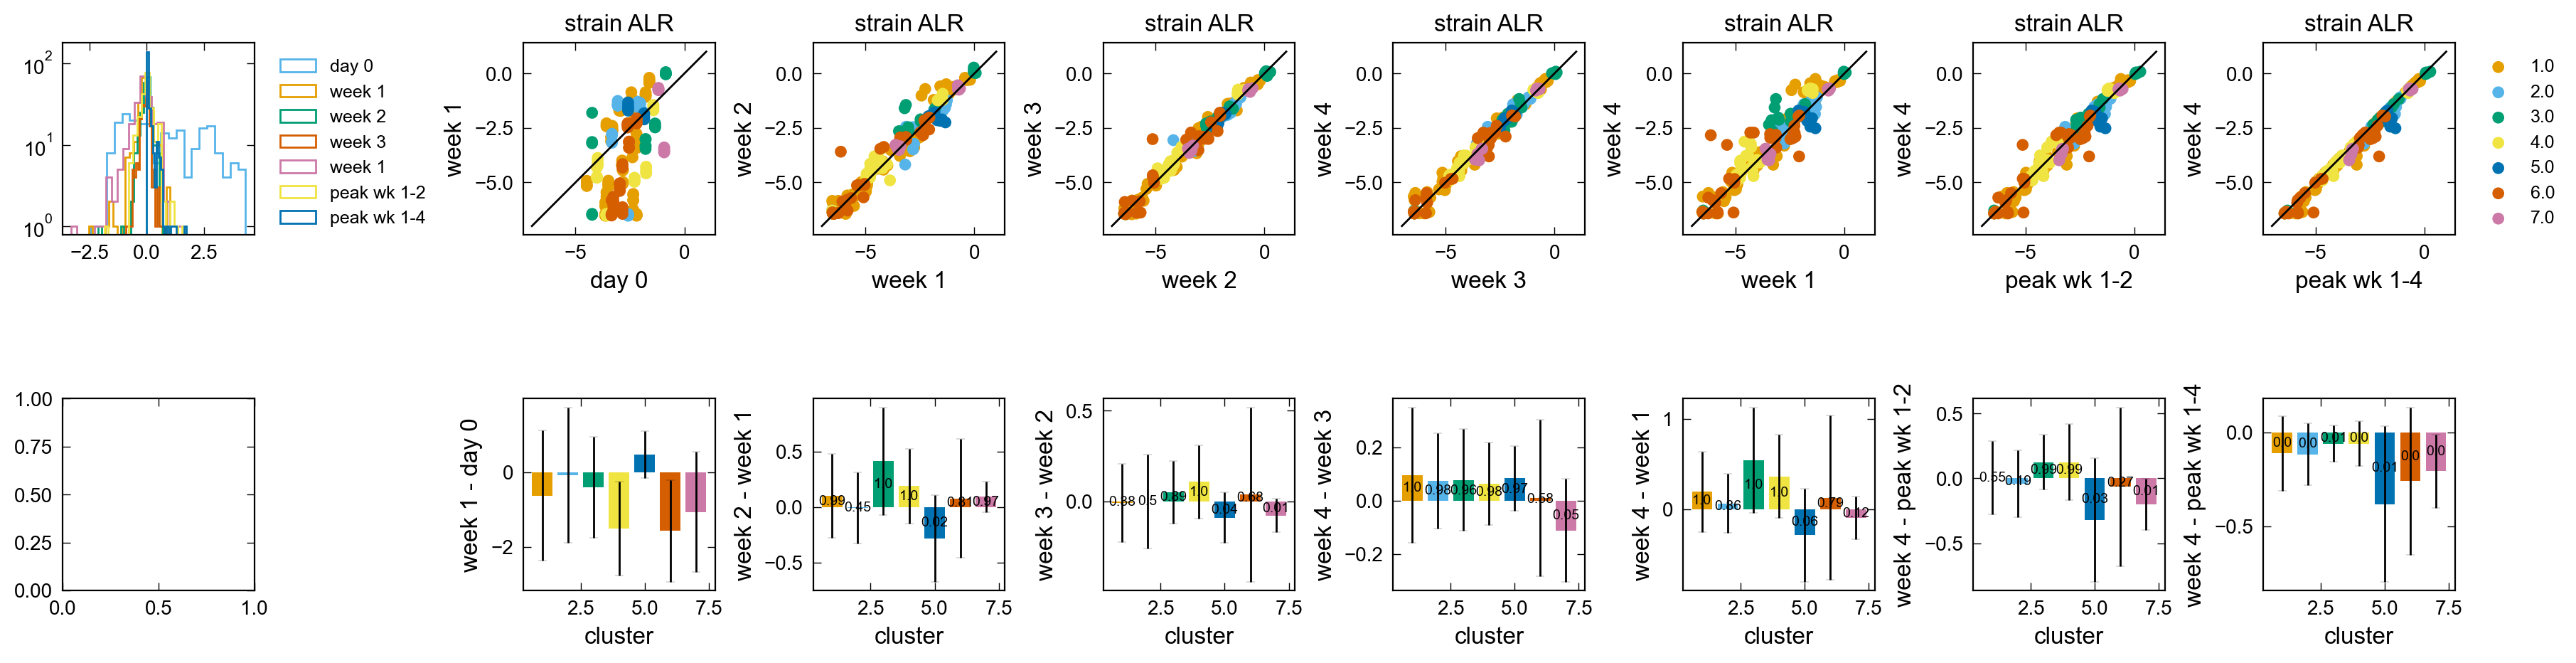

In [43]:
# Plot figures
fig, axs = plt.subplots(2, 8, figsize=(18.0, 5.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4'],  ['peak wk 1-2', 'week 4'], ['peak wk 1-4', 'week 4']]
var_list = [["day0_alr", "wk1_alr"],
            ["wk1_alr", "wk2_alr"],
            ["wk2_alr", "wk3_alr"],
            ["wk3_alr", "wk4_alr"],
            ["wk1_alr", "wk4_alr"],
            ["peak_1_2_alr", "wk4_alr"],
            ["peak_alr", "wk4_alr"]]

data = strain_alr_data.loc[strain_alr_data.cross_reactivity_cluster != 0]

for i, u in enumerate(var_list):
    axs[0, 0].hist(data[u[0]] - data[u[1]], bins = 20, log = True, histtype = 'step', label = labels[i]);
    axs[0, i + 1].plot(np.linspace(-7,1,10), np.linspace(-7,1,10), color = 'black')
    axs[0, i + 1].set_title('strain ALR', fontsize = 12)
        
    axs[0, i + 1].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i + 1].set_ylabel(labels[i][1], fontsize = 12)

    data.loc[:,'diff'] = (data[u[1]] - data[u[0]]).values
    
    bar_mean_data = data.drop(['replicate', 'strain_id'], axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    bar_std_data = data.drop(['replicate', 'strain_id'], axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()
    bars = axs[1, i + 1].bar(bar_mean_data['cross_reactivity_cluster'], bar_mean_data['diff'], 
                  color = bar_mean_data['cross_reactivity_cluster'].map(lut),
                  yerr=bar_std_data['diff'], capsize=2)
    axs[1, i + 1].set_ylabel(labels[i][1] +' - '+ labels[i][0], fontsize = 12)
    axs[1, i + 1].set_xlabel('cluster', fontsize = 12)
    p_labels = []
    
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i + 1].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
        m, b, r_value, p_value, std_err = scipy.stats.linregress(g[u[0]][mask], g[u[1]][mask])
        # axs[i + 1].plot(np.unique(g[u[0]][mask]), m*np.unique(g[u[0]][mask]) + b, 
        #                 color = g['cross_reactivity_cluster'].map(lut).tolist()[0],) 
                        #label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.3f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
        trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask], alternative = 'less')
        tind_stat, tind_p_value = ttest_ind(g[u[1]][mask], g[u[0]][mask], alternative = 'less', equal_var=False)
        res = wilcoxon(g[u[1]][mask] - g[u[0]][mask], alternative = 'less')
        wc_stat, wc_p_value = res.statistic, res.pvalue
        p_labels.append(np.round(trel_p_value, 2))
        
    if i >= 1:
        axs[1, i + 1].bar_label(bars, labels=p_labels, label_type = 'center', fontsize = 7)
       
for j, ax in enumerate(axs.flat):
    if j == 7 or j == 0:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

#fig.savefig('_figs/wk_change_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

['day 0', 'week 1']
cluster 0.000, wilcoxon P-value: 0.0000, t-test rel P-value: 0.0000, t-test ind P-value: 0.0001, reg slope: 0.4476, reg P-value: 0.0000
cluster 1.000, wilcoxon P-value: 0.9366, t-test rel P-value: 0.9987, t-test ind P-value: 0.9970, reg slope: 8.4010, reg P-value: 0.0000
cluster 2.000, wilcoxon P-value: 0.9945, t-test rel P-value: 0.9997, t-test ind P-value: 0.9993, reg slope: 0.6735, reg P-value: 0.1372
cluster 3.000, wilcoxon P-value: 0.4554, t-test rel P-value: 0.9737, t-test ind P-value: 0.9364, reg slope: 4.2318, reg P-value: 0.0000
cluster 4.000, wilcoxon P-value: 0.0000, t-test rel P-value: 0.0001, t-test ind P-value: 0.0052, reg slope: 0.3805, reg P-value: 0.0000
cluster 5.000, wilcoxon P-value: 0.8838, t-test rel P-value: 0.7977, t-test ind P-value: 0.8762, reg slope: -0.9238, reg P-value: 0.0011
cluster 6.000, wilcoxon P-value: 0.0000, t-test rel P-value: 0.0000, t-test ind P-value: 0.0026, reg slope: 0.6842, reg P-value: 0.0000
cluster 7.000, wilcoxon P-v

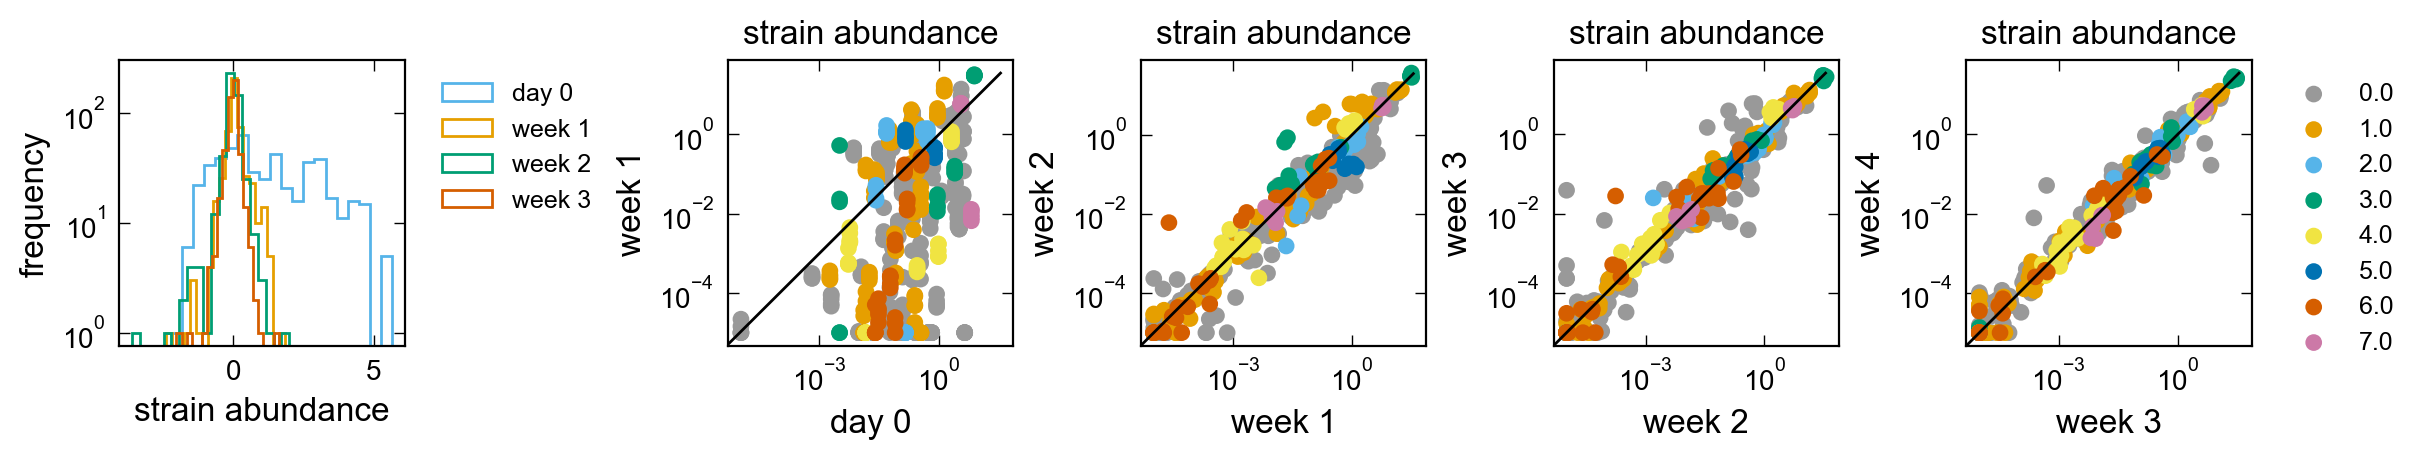

In [49]:
# Plot figures
fig, axs = plt.subplots(1, 5, figsize=(12.0, 3.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4']]
var_list = [["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"]]

data = strain_alr_data.loc[strain_alr_data.strain_id != 'nonimmunogenic_cluster']

for i, u in enumerate(var_list):
    print(labels[i + 1])
    axs[0].hist(np.log10(data[u[0]]/data[u[1]]), bins = 20, log = True, histtype = 'step', label = labels[i + 1]);
    axs[i + 1].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[i + 1].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
        m, b, r_value, p_value, std_err = scipy.stats.linregress(g[u[0]][mask], g[u[1]][mask])
        # axs[i + 1].plot(np.unique(g[u[0]][mask]), m*np.unique(g[u[0]][mask]) + b, 
        #                 color = g['cross_reactivity_cluster'].map(lut).tolist()[0],) 
                        #label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.3f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
        trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask], alternative = 'less')
        tind_stat, tind_p_value = ttest_ind(g[u[1]][mask], g[u[0]][mask], alternative = 'less', equal_var=False)
        res = wilcoxon(g[u[1]][mask] - g[u[0]][mask], alternative = 'less')
        wc_stat, wc_p_value = res.statistic, res.pvalue
        print(f"cluster {cluster:.3f}, wilcoxon P-value: {wc_p_value:.4f}, t-test rel P-value: {trel_p_value:.4f}, t-test ind P-value: {tind_p_value:.4f}, reg slope: {m:.4f}, reg P-value: {p_value:.4f}")
    
    
for j, ax in enumerate(axs.flat):
    if j == 4 or j == 0:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    if j >= 1:
        # ax.plot([0, 40], [0,40])
        ax.semilogy()
        ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

#fig.savefig('_figs/wk_change_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

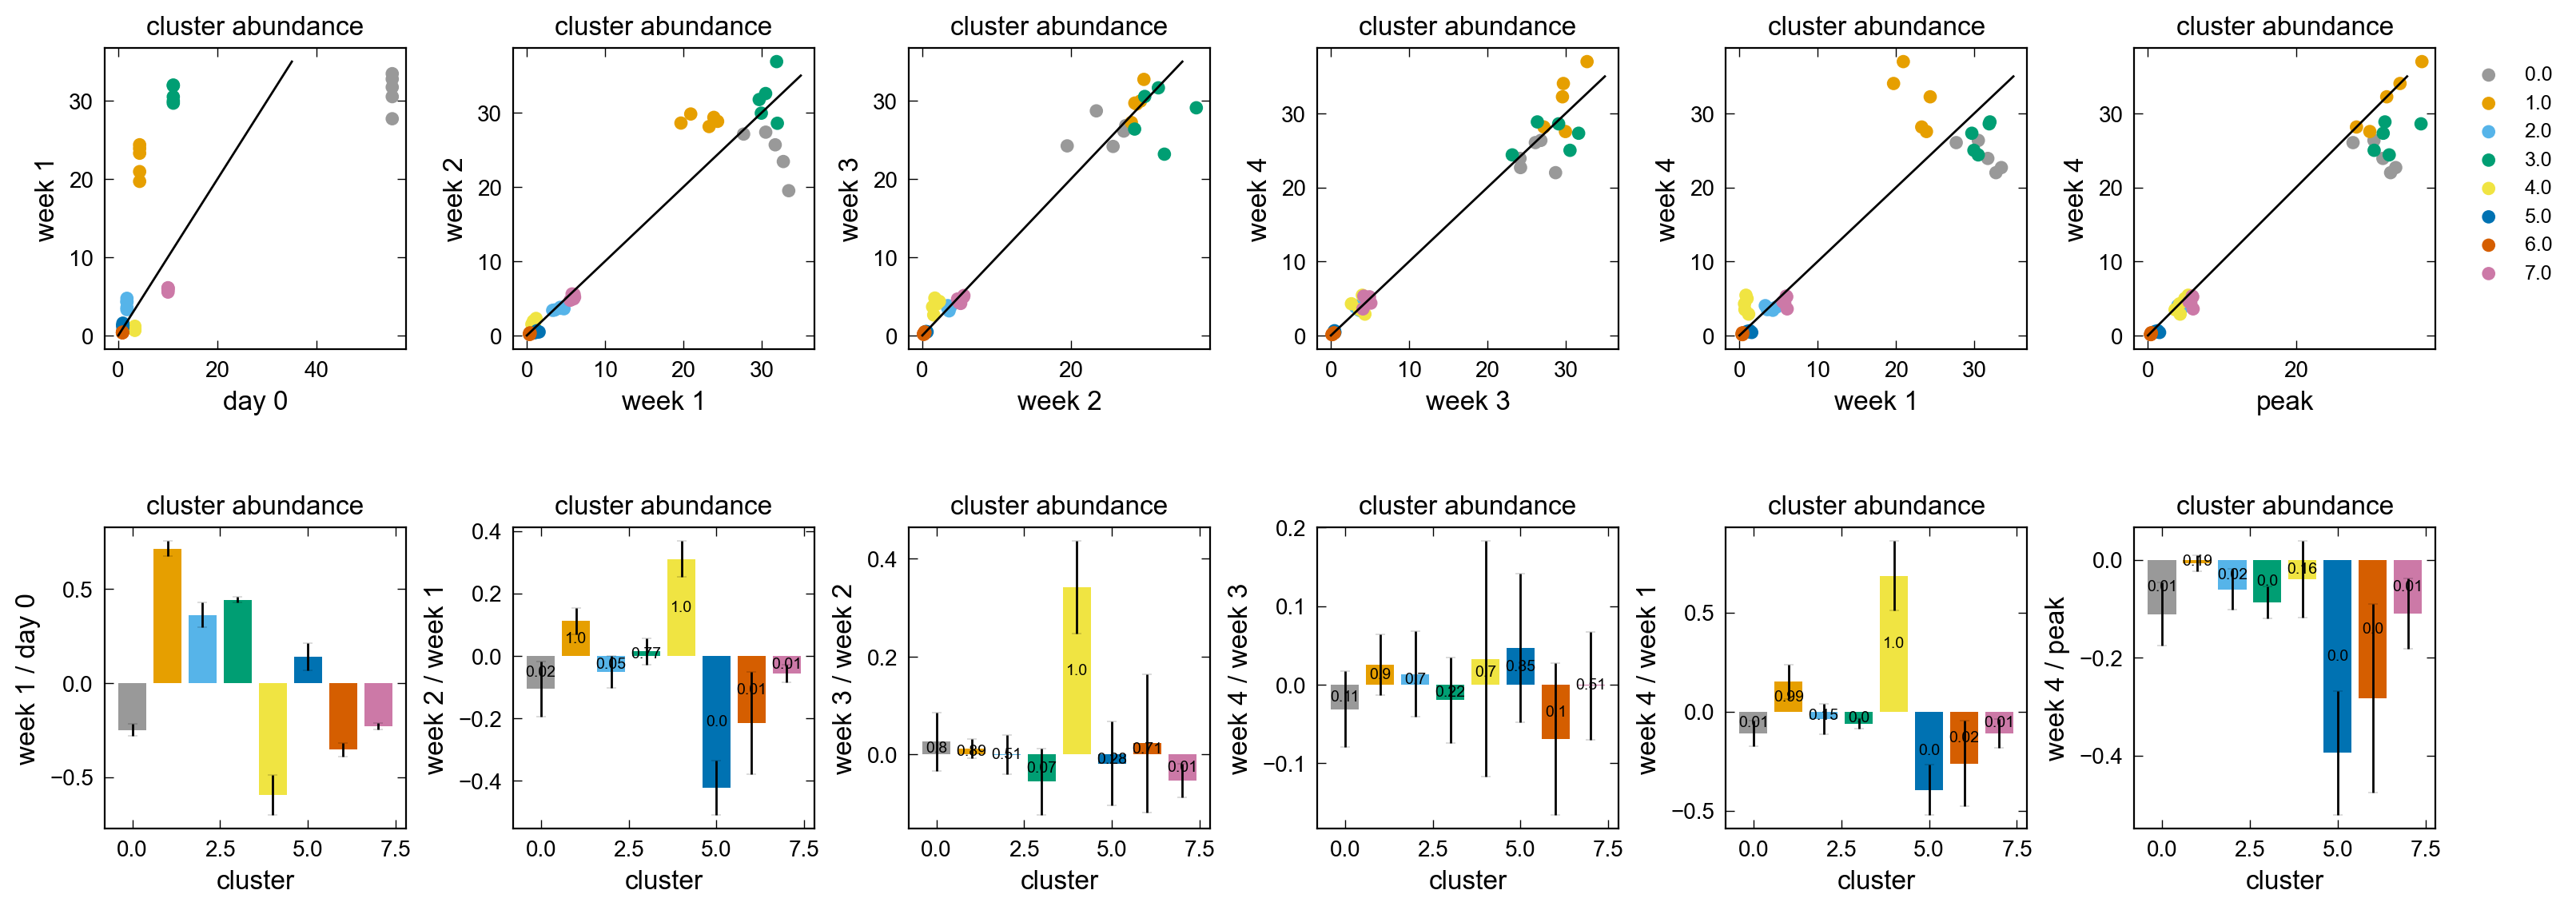

In [50]:
# Plot figures
fig, axs = plt.subplots(2, 6, figsize=(16.0, 6.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4'], ['peak', 'week 4']]
var_list = [["day0_abundance_batch1", "Batch1_week1"],
            ["Batch1_week1", "Batch1_week2"],
            ["Batch1_week2", "Batch1_week3"],
            ["Batch1_week3", "Batch1_week4"],
            ["Batch1_week1", "Batch1_week4"],
            ["Batch1_peak", "Batch1_week4"]]

data = cluster_alr_data

for i, u in enumerate(var_list):
    #print(labels[i])
    axs[0, i].plot(np.linspace(0,35,10), np.linspace(0,35,10), color = 'black')
    axs[0, i].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i].set_ylabel(labels[i][1], fontsize = 12)
    # axs[0, i].semilogy()
    # axs[0, i].semilogx()
    data.loc[:,'diff'] = np.log10(data[u[1]]/data[u[0]]).values
    
    bar_mean_data = data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    bar_std_data = data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()
    bars = axs[1, i].bar(bar_mean_data['cross_reactivity_cluster'], bar_mean_data['diff'], 
                  color = bar_mean_data['cross_reactivity_cluster'].map(lut),
                  yerr=bar_std_data['diff'], capsize=2)
    axs[1, i].set_ylabel(labels[i][1] +' / '+ labels[i][0], fontsize = 12)
    axs[1, i].set_xlabel('cluster', fontsize = 12)
    p_labels = []
    
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        
        if i >= 1:
            mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
            # m, b, r_value, p_value, std_err = scipy.stats.linregress(g[u[0]][mask], g[u[1]][mask])
            # axs[i].plot(np.unique(g[u[0]][mask]), m*np.unique(g[u[0]][mask]) + b, 
            #                 color = g['cross_reactivity_cluster'].map(lut).tolist()[0],) 
                            #label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.3f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
            
            trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask], alternative = 'less')
            tind_stat, tind_p_value = ttest_ind(g[u[1]][mask], g[u[0]][mask], alternative = 'less', equal_var=False)
            res = wilcoxon(g[u[1]][mask] - g[u[0]][mask], alternative = 'less')
            wc_stat, wc_p_value = res.statistic, res.pvalue
            #print(f"cluster {cluster:.3f}, wilcoxon P-value: {wc_p_value:.4f}, t-test rel P-value: {trel_p_value:.4f}, t-test ind P-value: {tind_p_value:.4f}") #, reg slope: {m:.4f}, reg P-value: {p_value:.4f}")
            
            p_labels.append(np.round(trel_p_value, 2))
    if i >= 1:
        axs[1, i].bar_label(bars, labels=p_labels, label_type = 'center', fontsize = 7)
    
for j, ax in enumerate(axs.flat):
    if j == 5:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    ax.set_title('cluster abundance', fontsize = 12) 
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)


Are the movements between cluster 0 and clusters 1 and 4 in concert?

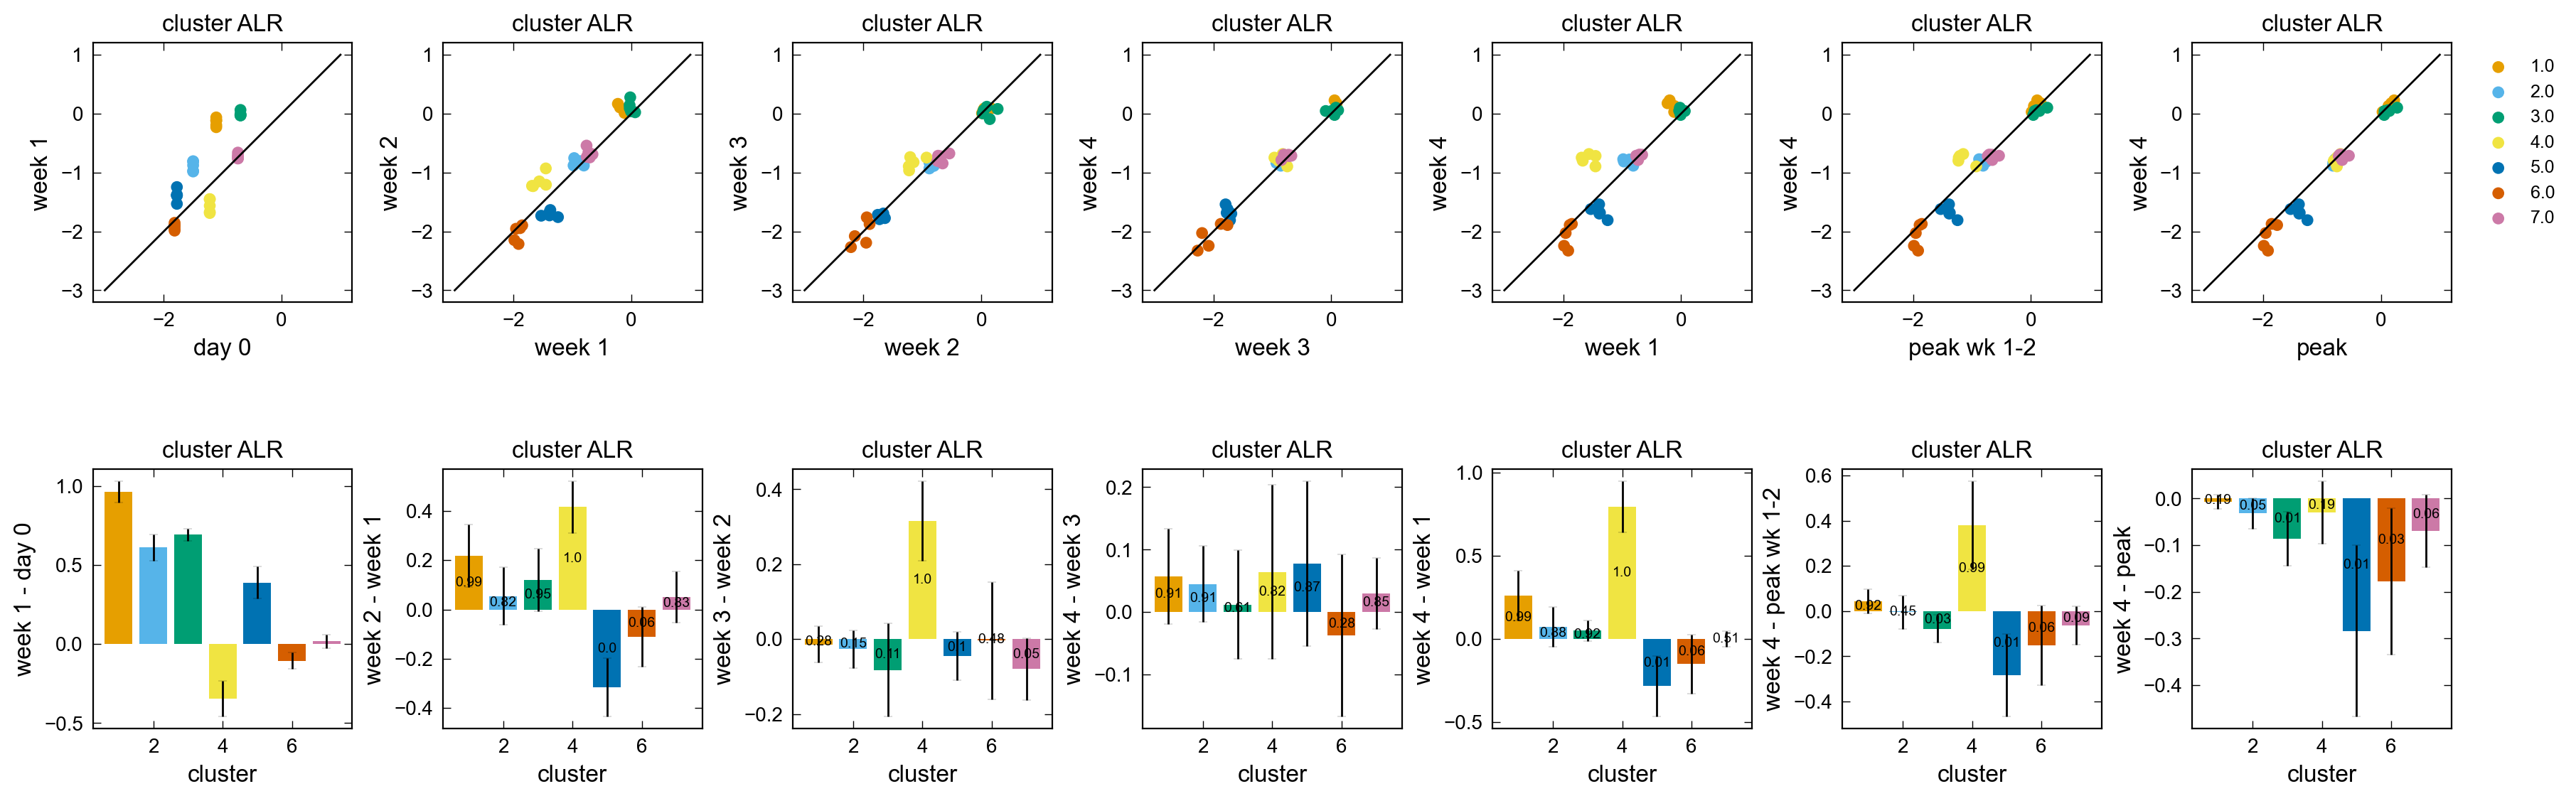

In [51]:
# Plot figures
fig, axs = plt.subplots(2, 7, figsize=(18.0, 6.0), sharex = False, constrained_layout=True)

labels = [['day 0', 'week 1'], ['week 1', 'week 2'], ['week 2', 'week 3'], ['week 3', 'week 4'], ['week 1', 'week 4'],  ['peak wk 1-2', 'week 4'], ['peak', 'week 4']]
var_list = [["day0_alr", "wk1_alr"],
            ["wk1_alr", "wk2_alr"],
            ["wk2_alr", "wk3_alr"],
            ["wk3_alr", "wk4_alr"],
            ["wk1_alr", "wk4_alr"],
            ["peak_1_2_alr", "wk4_alr"],
            ["peak_alr", "wk4_alr"]]

data = cluster_alr_data.loc[cluster_alr_data.cross_reactivity_cluster != 0]

for i, u in enumerate(var_list):
    # print(labels[i])
    axs[0, i].plot(np.linspace(-3,1,10), np.linspace(-3,1,10), color = 'black')
    axs[0, i].set_xlabel(labels[i][0], fontsize = 12)
    axs[0, i].set_ylabel(labels[i][1], fontsize = 12)
    data.loc[:,'diff'] = (data[u[1]] - data[u[0]]).values
    
    bar_mean_data = data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()
    bar_std_data = data.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()
    bars = axs[1, i].bar(bar_mean_data['cross_reactivity_cluster'], bar_mean_data['diff'], 
                  color = bar_mean_data['cross_reactivity_cluster'].map(lut),
                  yerr=bar_std_data['diff'], capsize=2)
    axs[1, i].set_ylabel(labels[i][1] +' - '+ labels[i][0], fontsize = 12)
    axs[1, i].set_xlabel('cluster', fontsize = 12)
    
    p_labels = []
    for (_, g) in data.groupby('cross_reactivity_cluster'):
        cluster = g['cross_reactivity_cluster'].values[0]
        axs[0, i].scatter(g[u[0]], g[u[1]], marker = 'o', color = g['cross_reactivity_cluster'].map(lut), label = cluster)
        
        if i >= 1:
            mask = ~np.isnan(g[u[0]]) & ~np.isnan(g[u[1]])
            # m, b, r_value, p_value, std_err = scipy.stats.linregress(g[u[0]][mask], g[u[1]][mask])
            # axs[i].plot(np.unique(g[u[0]][mask]), m*np.unique(g[u[0]][mask]) + b, 
            #                 color = g['cross_reactivity_cluster'].map(lut).tolist()[0],) 
                            #label = r'$R^2$: ' + str("{:.2f}".format(r_value**2)) + r', $m$: ' + str("{:.3f}".format(m)) + ',\n'+r'$p$: ' + str("{:.3f}".format(p_value)))
            
            trel_stat, trel_p_value = ttest_rel(g[u[1]][mask], g[u[0]][mask], alternative = 'less')
            tind_stat, tind_p_value = ttest_ind(g[u[1]][mask], g[u[0]][mask], alternative = 'less', equal_var=False)
            res = wilcoxon(g[u[1]][mask] - g[u[0]][mask], alternative = 'less')
            wc_stat, wc_p_value = res.statistic, res.pvalue
            # print(f"cluster {cluster:.3f}, wilcoxon P-value: {wc_p_value:.4f}, t-test rel P-value: {trel_p_value:.4f}, t-test ind P-value: {tind_p_value:.4f}") #, reg slope: {m:.4f}, reg P-value: {p_value:.4f}")
            
            p_labels.append(np.round(trel_p_value, 2))
    if i >= 1:
        axs[1, i].bar_label(bars, labels=p_labels, label_type = 'center', fontsize = 7)
    
for j, ax in enumerate(axs.flat):
    if j == 6:
        ax.legend(bbox_to_anchor=(1.05, 1.0), fontsize=9, framealpha=0)
    ax.set_title('cluster ALR', fontsize = 12) 
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

#fig.savefig('_figs/wk_change_in_abundance_strain'+'.pdf', dpi=300, bbox_inches='tight')

Rework to use both relative abundance and ALR; compare wk4 - wk1  and wk4 - peak

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


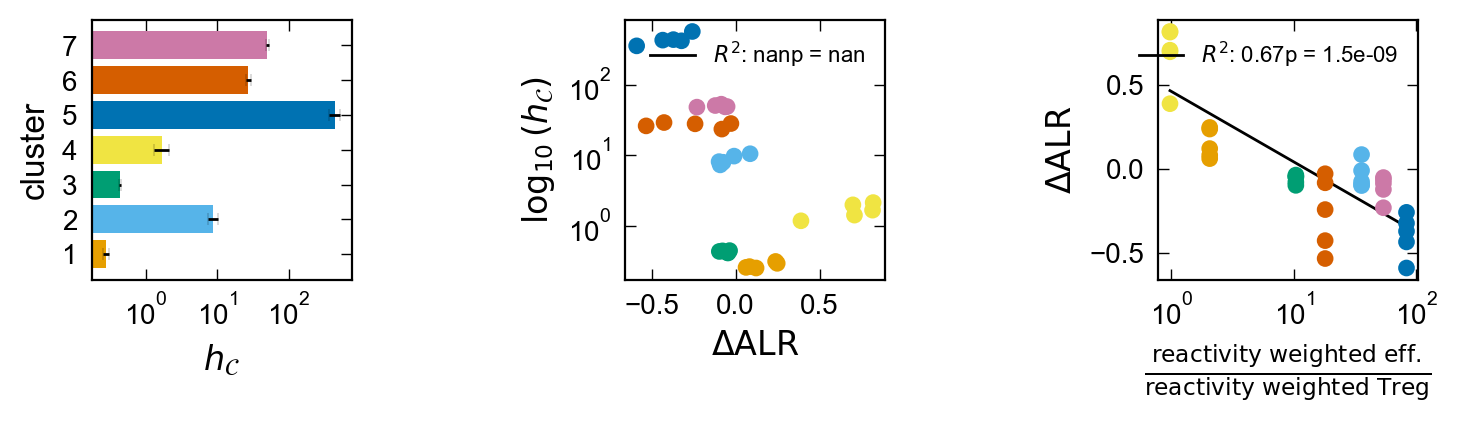

In [45]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'

fig, axs = plt.subplots(1, 3, figsize=(8.0, 2.0), sharex = False, constrained_layout=True)

cluster_react_fig_data = cross_reac_fig_data[['cross_reactivity_cluster', 'mean_sigma']].groupby('cross_reactivity_cluster', as_index = False).mean()
hybridoma_abundance_fig_data = hybridoma_cluster_data.drop('strain_id', axis=1).groupby('cross_reactivity_cluster', as_index = False).mean()
# plot figure (b)
for_figb = cluster_alr_data.loc[cluster_alr_data.cross_reactivity_cluster != 0].merge(cluster_react_fig_data, how = 'left', on = 'cross_reactivity_cluster', 
                                                                                      validate = 'many_to_one').merge(hybridoma_abundance_fig_data, how = 'left', on = 'cross_reactivity_cluster', validate = 'many_to_one').replace([np.inf, -np.inf, np.nan], 0)
for_figb.loc[:, 'del_alr'] =  np.log10(for_figb['Batch1_week4']/for_figb['Batch1_week1']) #for_figb['wk4_alr'] - for_figb['wk1_alr'] #
for_figb.loc[:, 'eff_Treg_ratio'] = for_figb['total_effector']/for_figb['total_Treg']
# for_figb.loc[:, 'est_h'] = -2*(for_figb['del_alr'] - for_figb['del_alr'][0]).values - np.log10(for_figb['mean_sigma']/for_figb['mean_sigma'][0]).values - (for_figb['peak_alr'] - for_figb['peak_alr'][0]).values
for_figb.loc[:, 'est_h'] = ((1 + np.sqrt(for_figb['mean_sigma'])*for_figb['eff_Treg_ratio'])**2/for_figb['Batch1_week1']).values


x_data = for_figb.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()['cross_reactivity_cluster']
y_data = for_figb.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).mean()['est_h']
err = for_figb.drop('replicate', axis = 1).groupby('cross_reactivity_cluster', as_index = False).std()['est_h']

axs[0].barh(x_data, y_data, color = x_data.map(lut), xerr=err, capsize=2)
axs[0].semilogx()
axs[0].set_yticks(x_data)
# axs[1].scatter(y_data[4], x_data[4], color = 'black', marker = 'X')

# plot figure (c)
x_data = for_figb['del_alr'] #/(10**for_figb['peak_alr'].values)
y_data = for_figb['est_h']

axs[1].scatter(x_data, y_data, color = for_figb['cross_reactivity_cluster'].map(lut))
m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)
axs[1].plot(x_data, 
        m*x_data + b,
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f'p = {p_value:.1e}')


# plot figure (d)
# for_figd = hybridoma_cluster_data.merge(strain_data[['strain_id','day0_abundance_batch1_alr', 'wk1_mean_abundance_alr', 'wk2_mean_abundance_alr','wk3_mean_abundance_alr','wk4_mean_abundance_alr']], how = 'left', on = 'strain_id', validate = 'one_to_one')
# for_figd.loc[:, 'max_abundance'] = np.amax(for_figd[['wk1_mean_abundance_alr', 'wk2_mean_abundance_alr']], axis = 1)
# for_figd.loc[:, 'del_abundance'] = for_figd['wk3_mean_abundance_alr'] - for_figd['max_abundance']
# for_figdii = for_figd.drop('strain_id', axis=1).groupby('cross_reactivity_cluster', as_index = False).mean()

# # plot strains
# x_data = for_figb['total_effector']/for_figd['total_Treg']
# y_data = for_figb['del_alr']
# axs[3].scatter(x_data, y_data, s = 5, color = 'grey', zorder = 0)

# plot clusters
x_data = for_figb['total_effector']/for_figb['total_Treg']
y_data = for_figb['del_alr']
axs[2].scatter(x_data, y_data, s = 25, color = for_figb['cross_reactivity_cluster'].map(lut), zorder = 2)
# axs[3].plot(np.unique(x_data), -np.log10(1 + np.unique(x_data)), color = 'red')

m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data), y_data)
axs[2].plot(np.unique(x_data), 
        m*np.unique(np.log10(x_data)) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f'p = {p_value:.1e}')


# Format figure
for j, ax in enumerate(axs.flat):
    if j == 0:
        ax.set_ylabel('cluster', fontsize = 12)
        ax.set_xlabel(r'$h_\mathcal{C}$', fontsize = 12)
    elif j == 1:
        ax.set_xlabel(r'$\Delta\text{ALR}$', fontsize = 12)
        ax.set_ylabel(r'$\log_{10}(h_\mathcal{C})$', fontsize = 12)
        ax.legend(fontsize=8)
        ax.semilogy()
    elif j == 2:
        ax.set_xlabel(r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$', fontsize = 12)
        ax.set_ylabel(r'$\Delta\text{ALR}$', fontsize = 12)
        ax.legend(fontsize=8)
        ax.semilogx()
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

fig.savefig('_figs/fig_estimated_harm_by_cluster'+'.pdf', dpi=300, bbox_inches='tight')

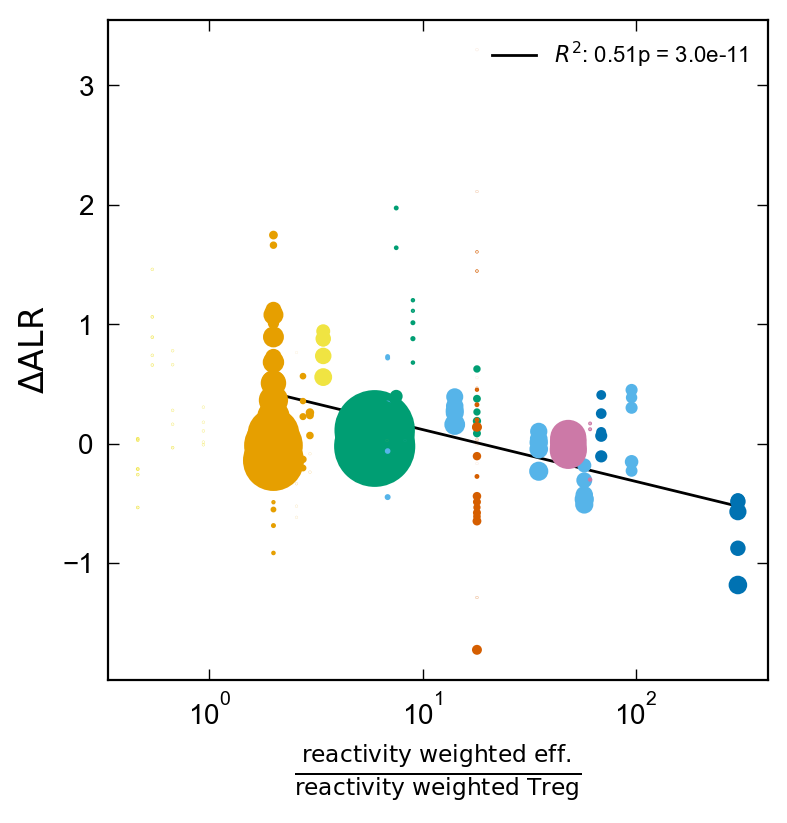

In [41]:
# Plot figures
plot_variables = ['GF_Th17_Average', 'hCom1d_Th17_Average']
cluster_variable= 'cross_reactivity_cluster'

fig, axs = plt.subplots(1, 1, figsize=(4, 4.0), sharex = False, constrained_layout=True)

cluster_react_fig_data = cross_reac_fig_data[['mean_sigma', 'strain_id']]
hybridoma_abundance_fig_data = hybridoma_cluster_data.drop('cross_reactivity_cluster', axis = 1)
# plot figure (b)
for_fig = strain_alr_data.loc[strain_alr_data.cross_reactivity_cluster != 0].merge(cluster_react_fig_data, how = 'left', on = 'strain_id', 
                                                                                      validate = 'many_to_one').merge(hybridoma_abundance_fig_data, 
                                                                                                                      how = 'left', on = 'strain_id', validate = 'many_to_one').replace([np.inf, -np.inf, np.nan], 0)
for_fig.loc[:, 'del_alr'] =  for_fig['wk4_alr'] - for_fig['wk1_alr'] #np.log10(np.maximum(1e-5, for_fig['Batch1_week4'])/np.maximum(1e-5,for_fig['Batch1_week1']))

x_data = (for_fig['total_effector']/for_fig['total_Treg']).replace([np.inf, -np.inf], np.nan)
y_data = for_fig['del_alr'] #.replace([np.inf, -np.inf, np.nan], 1)
axs.scatter(x_data, y_data, s = 25*for_fig['Batch1_week1'], color = for_fig['cross_reactivity_cluster'].map(lut), zorder = 2)
# axs[3].plot(np.unique(x_data), -np.log10(1 + np.unique(x_data)), color = 'red')

mask = for_fig['Batch1_week1'] > 5e-1
m, b, r_value, p_value, std_err = scipy.stats.linregress(np.log10(x_data[mask]), y_data[mask])
axs.plot(np.unique(x_data[mask]), 
        m*np.unique(np.log10(x_data[mask])) + b, 
              color = 'black',
              zorder = 0,
              linewidth = 1.0,
        label = r'$R^2$: ' + str("{:.2f}".format(r_value**2))+ f'p = {p_value:.1e}')


# Format figure
axs.set_xlabel(r'$\frac{\text{reactivity weighted eff.}}{\text{reactivity weighted Treg}}$', fontsize = 12)
axs.set_ylabel(r'$\Delta\text{ALR}$', fontsize = 12)
axs.legend(fontsize=8)
axs.semilogx()

axs.set_box_aspect(1)
axs.minorticks_off()
axs.tick_params(axis='both', which='major', labelsize=10)
axs.xaxis.set_tick_params(labeltop=False)

#fig.savefig('_figs/fig_estimated_harm_by_cluster'+'.pdf', dpi=300, bbox_inches='tight')

Take full advantage of ecological replicates. Use them in computations and especially when you do regressions to improve statistical power. fix figure d. Use wilcoxon signed-rank test to test for differences between week t1 and t2. Can consider

In [42]:
full_data_w_clusters[[cluster_variable, 'day0_abundance_batch1','wk1_mean_abundance', 'wk2_mean_abundance','wk3_mean_abundance','wk4_mean_abundance']].groupby(cluster_variable, as_index = False).sum()

KeyError: "['wk1_mean_abundance', 'wk2_mean_abundance', 'wk3_mean_abundance', 'wk4_mean_abundance'] not in index"

Note that cluster 4 only has regulatory T-cell coverage present.

In [ ]:
# pd.set_option('display.max_rows', None)
# strain_data[['cross_reactivity_cluster', 'wk2_mean_abundance', 'strain_id']]

In [ ]:
# ALR makes sense as a quantity of interest. It conveniently removes the total biomass from the abundance relationship between two species and is something my model can predict.
# (1) Want to regress week 2 - week 4 change in alr on mean (maybe geometric) immune coverage within the cluster. Is there signal?
# (2) Compare all species within the immune-covered clusters to the reference (non-immune coverage) cluster
# (3) Combine strain and amino acid dropout variables into a single clustering step

In [ ]:
# Plot figures
fig, ax = plt.subplots(1, 1, figsize=(2.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var = 'wk2_mean_abundance'

data = full_data_w_clusters.loc[full_data_w_clusters[var] > 0]
start, stop = np.log10(np.nanmin(data[var])), np.log10(np.nanmax(data[var]))
log_bins = 10**np.linspace(start, stop, 10)
# bins = np.linspace(start, stop, 50)

# for k, (_,g) in enumerate(full_data_w_clusters.groupby(['cross_reactivity_cluster'], as_index = False)):
ax.hist(data.loc[data.imm_resp_flag <= 0][var], log = True, 
        bins = log_bins, histtype = 'step', density=True, color = 'gray', 
        linewidth=1.5, label = 'non-immunogenic')
ax.hist(data.loc[data.imm_resp_flag > 0][var], log = True, 
        bins = log_bins, histtype = 'step', density=True, color = 'red', 
        linewidth=1.5, label = 'immunogenic')
    
ax.legend(fontsize=8, framealpha=0, loc = 'upper right')

ax.set_ylabel('counts', fontsize = 12)
ax.set_xlabel('week 1\n relative abundance', fontsize = 12)
ax.semilogx()
ax.set_box_aspect(1)
ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)

print(len(data.loc[data.imm_resp_flag <= 0][var]), len(data.loc[data.imm_resp_flag > 0][var]))

# Run two-sided Mann-Whitney test with null that the two distribitions are identical
from scipy.stats import mannwhitneyu
U1, p = mannwhitneyu(data.loc[data.imm_resp_flag <= 0][var], data.loc[data.imm_resp_flag > 0][var], method="exact")
print(p)

fig.savefig('_figs/fig_hist_rel_abundance_by_imm'+'.pdf', dpi=300, bbox_inches='tight')

Do a two-sided Mann-Whitney test for statistical significance between distributions.

In [ ]:
# for i, c in enumerate(cluster_variables):
#     counts_specific_column = full_data_w_clusters.loc[full_data_w_clusters.Phyla.notna()].fillna(-1).groupby([cluster_variables[i % len(cluster_variables)], cluster_variables[(i + 1) % len(cluster_variables)]])['strain_id'].count()
#     # out = pd.crosstab(full_data_w_clusters[cluster_variables[i % len(cluster_variables)], cluster_variables[(i + 1) % len(cluster_variables)]],
#     #                    full_data_w_clusters['strain_id'])
#     print("\nCounts of 'Strains' using count():")
#     print(counts_specific_column)

In [ ]:
input_data = full_data_w_clusters.groupby(['cross_reactivity_cluster', 'Phyla']).size().reset_index(name='count')
hmap_data= pd.pivot_table(input_data, values='count', index='Phyla', columns='cross_reactivity_cluster')
fig, ax = plt.subplots(figsize=(3, 2))
sns.heatmap(hmap_data, annot=True, linewidths=.5, ax=ax)
ax.set(xlabel="cluster", ylabel="phyla")

for _, spine in ax.spines.items():
    spine.set_visible(True)
    spine.set_edgecolor('black') # Set the color of the outline
    spine.set_linewidth(2)      # Set the width of the outline

ax.minorticks_off()
ax.tick_params(axis='both', which='major', labelsize=10)
ax.xaxis.set_tick_params(labeltop=False)
ax.tick_params(axis='y', labelrotation=0)
# ax.tick_params(axis='x', labelrotation=315)
fig.savefig('_figs/fig_hmap_phyla_cluster_overlap'+'.pdf', dpi=300, bbox_inches='tight')